<a href="https://colab.research.google.com/github/razorbladesky/ruta-inundacion-ia/blob/main/simulacion_inundacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

# ==========================================
# 1. CONSTANTES DE CONFIGURACIÓN
# ==========================================

# Representa un obstáculo infranqueable (pared o zona inaccesible)
BLOQUEADO = -1

# Niveles de inundación en las celdas transitables
SECO = 0
RIESGO_BAJO = 1
RIESGO_MEDIO = 2
RIESGO_ALTO = 3

# Diccionario de costos de entrada a cada tipo de celda transitable
# A mayor nivel de inundación, mayor es el esfuerzo (costo) para cruzar la celda
COSTOS = {
    SECO: 1,          # Tránsito normal
    RIESGO_BAJO: 3,   # Agua a los tobillos
    RIESGO_MEDIO: 6,  # Agua a las rodillas
    RIESGO_ALTO: 10   # Corriente fuerte, requiere mucho cuidado
}

# ==========================================
# 2. CREACIÓN DEL MAPA
# ==========================================

def crear_mapa_principal():
    """
    Crea y devuelve el mapa de la simulación de 10x10.
    Los valores representan el nivel de riesgo de inundación o si está bloqueado.
    """
    mapa_lista = [
        [ 0,  0,  0,  1,  0, -1,  0,  0,  1,  0],
        [ 0,  0,  1,  1,  0, -1,  0,  1,  0,  0],
        [ 0,  1,  1,  1,  1,  3,  1,  1,  1,  0],
        [ 0,  0,  2,  2,  1, -1,  1,  2,  0,  0],
        [ 0,  0,  2,  3,  1, -1,  1,  3,  2,  0],
        [ 0,  1,  2,  3,  2, -1,  2,  2,  1,  0],
        [ 0,  0,  1,  2,  1, -1,  1,  1,  0,  0],
        [ 0,  0,  0,  1,  0, -1,  0,  0,  0,  0],
        [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 0,  0,  1,  1,  0, -1,  0,  1,  0,  0]
    ]
    return np.array(mapa_lista)

# ==========================================
# 3. COORDENADAS DE INICIO Y DESTINO
# ==========================================
# Formato (fila, columna)
INICIO = (2, 0)
REFUGIO = (2, 9)

# ==========================================
# 4. FUNCIÓN PARA IMPRIMIR EL MAPA
# ==========================================

def imprimir_mapa(mapa, inicio, refugio):
    """
    Imprime una representación visual del mapa en consola.
    - 'I' representa la posición inicial.
    - 'R' representa el refugio seguro.
    - '#' representa las zonas bloqueadas (-1).
    - Los números representan el nivel de inundación (0, 1, 2, 3).
    """
    filas, columnas = mapa.shape

    for f in range(filas):
        fila_texto = []
        for c in range(columnas):
            coordenada_actual = (f, c)
            valor = mapa[f, c]

            # Prioridad de dibujado: Inicio -> Refugio -> Obstáculos/Terreno
            if coordenada_actual == inicio:
                fila_texto.append('I')
            elif coordenada_actual == refugio:
                fila_texto.append('R')
            elif valor == BLOQUEADO:
                fila_texto.append('#')
            else:
                fila_texto.append(str(valor))

        # Unimos los elementos con un espacio para que se vea ordenado y cuadrado
        print(" ".join(fila_texto))

# ==========================================
# 5. EJECUCIÓN Y PRUEBA
# ==========================================

# Inicializamos el mapa
mapa_simulacion = crear_mapa_principal()

# Mostramos las dimensiones del mapa
print(f"Dimensiones del mapa generado: {mapa_simulacion.shape} (10 filas x 10 columnas)\n")

# Imprimimos la representación visual del mapa
print("Visualización del mapa (I = Inicio, R = Refugio, # = Bloqueado):")
imprimir_mapa(mapa_simulacion, INICIO, REFUGIO)

Dimensiones del mapa generado: (10, 10) (10 filas x 10 columnas)

Visualización del mapa (I = Inicio, R = Refugio, # = Bloqueado):
0 0 0 1 0 # 0 0 1 0
0 0 1 1 0 # 0 1 0 0
I 1 1 1 1 3 1 1 1 R
0 0 2 2 1 # 1 2 0 0
0 0 2 3 1 # 1 3 2 0
0 1 2 3 2 # 2 2 1 0
0 0 1 2 1 # 1 1 0 0
0 0 0 1 0 # 0 0 0 0
0 0 0 0 0 0 0 0 0 0
0 0 1 1 0 # 0 1 0 0


In [ ]:
def obtener_vecinos(mapa, celda):
    """
    Devuelve los vecinos válidos de una celda en el siguiente orden fijo:
    arriba, derecha, abajo, izquierda.
    Un vecino es válido si está dentro de los límites y no está BLOQUEADO.
    """
    fila, col = celda
    filas_max, columnas_max = mapa.shape
    vecinos_validos = []

    # Movimientos posibles en el orden requerido:
    # Arriba (-1, 0), Derecha (0, +1), Abajo (+1, 0), Izquierda (0, -1)
    movimientos = [
        (fila - 1, col),  # Arriba
        (fila, col + 1),  # Derecha
        (fila + 1, col),  # Abajo
        (fila, col - 1)   # Izquierda
    ]

    for f, c in movimientos:
        # 1. Verificar límites de la matriz
        if 0 <= f < filas_max and 0 <= c < columnas_max:
            # 2. Verificar que no esté bloqueado
            if mapa[f, c] != BLOQUEADO:
                vecinos_validos.append((f, c))

    return vecinos_validos


def costo_de_ruta(mapa, ruta):
    """
    Calcula el costo total de transitar por una ruta.
    La primera celda (inicio) no suma costo.
    Retorna None si la ruta es inválida, vacía o toca zonas bloqueadas.
    """
    # Validación de ruta nula o vacía
    if ruta is None or len(ruta) < 1:
        return None

    costo_total = 0

    # Recorremos cada celda de la ruta indicando su posición (índice)
    for i, celda in enumerate(ruta):
        f, c = celda
        valor_celda = mapa[f, c]

        # Si la celda está bloqueada, la ruta es inválida
        if valor_celda == BLOQUEADO:
            return None

        # El inicio (índice 0) no suma costo
        if i > 0:
            costo_total += COSTOS[valor_celda]

    return costo_total

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# Usamos el mapa cargado en la celda anterior
mapa = mapa_simulacion

# Prueba 1: Vecinos en (2, 0) -> Arriba, Derecha, Abajo (Izquierda está fuera de límites)
assert obtener_vecinos(mapa, (2, 0)) == [(1, 0), (2, 1), (3, 0)], "Error en vecinos de (2, 0)"

# Prueba 2: Vecinos en (0, 0) -> Derecha, Abajo (Arriba e Izquierda fuera de límites)
assert obtener_vecinos(mapa, (0, 0)) == [(0, 1), (1, 0)], "Error en vecinos de (0, 0)"

# Prueba 3: Vecinos en (1, 4) -> Arriba, Abajo, Izquierda (Derecha (1, 5) es bloqueado '#')
assert obtener_vecinos(mapa, (1, 4)) == [(0, 4), (2, 4), (1, 3)], "Error en vecinos de (1, 4)"

# Prueba 4: Costo de la ruta directa horizontal de fila 2: desde (2, 0) hasta (2, 9)
ruta_fila_2 = [(2, i) for i in range(10)]
assert costo_de_ruta(mapa, ruta_fila_2) == 32, f"Error: se esperaba costo 32, pero se obtuvo {costo_de_ruta(mapa, ruta_fila_2)}"

# Prueba 5: Costo de ruta con una sola celda (solo inicio)
assert costo_de_ruta(mapa, [(2, 0)]) == 0, "Error: la ruta de un solo paso debe costar 0"

# Prueba 6: Ruta que pasa por un obstáculo bloqueado (0, 5)
ruta_con_bloqueo = [(0, 4), (0, 5), (0, 6)]
assert costo_de_ruta(mapa, ruta_con_bloqueo) is None, "Error: ruta con bloqueos debe retornar None"

print("Parte 2: todas las pruebas pasaron")

Parte 2: todas las pruebas pasaron


In [ ]:
from collections import deque

def bfs(mapa, inicio, refugio):
    """
    Implementa búsqueda en anchura (BFS) para encontrar la ruta con menos pasos.
    Devuelve una tupla (ruta, costo, nodos_expandidos).
    """
    # Caso 1: Si la celda de inicio está bloqueada, no hay búsqueda
    if mapa[inicio] == BLOQUEADO:
        return (None, None, 0)

    # Caso 2: Si el inicio ya es el refugio
    if inicio == refugio:
        return ([inicio], 0, 1)

    # Inicialización de la cola de exploración y el conjunto de visitados
    # Guardamos tuplas con (celda_actual)
    cola = deque([inicio])

    # Marcamos como visitada al meterla en la cola
    visitados = {inicio}

    # Diccionario para rastrear de dónde venimos y reconstruir el camino
    padres = {inicio: None}

    nodos_expandidos = 0

    # Bucle principal de BFS
    while cola:
        # Sacar el primer nodo de la cola (FIFO) y contabilizar su expansión
        actual = cola.popleft()
        nodos_expandidos += 1

        # Si llegamos al refugio al SACARLO, terminamos
        if actual == refugio:
            break

        # Obtener los vecinos válidos usando la función definida anteriormente
        vecinos = obtener_vecinos(mapa, actual)

        for vecino in vecinos:
            if vecino not in visitados:
                # Marcar al METER en la cola
                visitados.add(vecino)
                padres[vecino] = actual
                cola.append(vecino)

    # Si salimos del bucle y el refugio nunca se visitó, no es alcanzable
    if refugio not in visitados:
        return (None, None, nodos_expandidos)

    # Reconstrucción del camino desde el refugio hacia el inicio
    ruta = []
    actual = refugio
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]

    # Invertimos la ruta para tenerla de inicio a fin
    ruta.reverse()

    # Calcular costo de entrada usando la función costo_de_ruta creada antes
    costo = costo_de_ruta(mapa, ruta)

    return (ruta, costo, nodos_expandidos)

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# 1. Prueba en mapa principal
ruta_bfs, costo_bfs, expandidos_bfs = bfs(mapa_simulacion, INICIO, REFUGIO)
assert ruta_bfs == [(2, i) for i in range(10)], "Error: La ruta obtenida no es la directa por la fila 2"
assert costo_bfs == 32, f"Error: El costo debería ser 32, se obtuvo {costo_bfs}"
assert len(ruta_bfs) - 1 == 9, "Error: La cantidad de pasos (aristas) debe ser 9"

# 2. Prueba con inicio == refugio
r_mismo, c_mismo, e_mismo = bfs(mapa_simulacion, INICIO, INICIO)
assert r_mismo == [INICIO] and c_mismo == 0 and e_mismo == 1, "Error en caso inicio == refugio"

# 3. Prueba aislando el refugio (bloqueando sus entradas: (1,9), (3,9), (2,8))
mapa_aislado = mapa_simulacion.copy()
mapa_aislado[1, 9] = BLOQUEADO
mapa_aislado[3, 9] = BLOQUEADO
mapa_aislado[2, 8] = BLOQUEADO
r_aislado, c_aislado, e_aislado = bfs(mapa_aislado, INICIO, REFUGIO)
assert r_aislado is None, "Error: el refugio no debería ser alcanzable"
assert c_aislado is None, "Error: el costo debe ser None para rutas imposibles"
assert e_aislado > 0, "Error: se deben haber expandido nodos antes de darse por vencido"

# 4. Prueba con inicio bloqueado
mapa_bloq_inicio = mapa_simulacion.copy()
mapa_bloq_inicio[INICIO] = BLOQUEADO
r_bloq, c_bloq, e_bloq = bfs(mapa_bloq_inicio, INICIO, REFUGIO)
assert r_bloq is None and c_bloq is None and e_bloq == 0, "Error: inicio bloqueado debe devolver (None, None, 0)"

print("Parte 3: todas las pruebas pasaron\n")

# ==========================================
# EJECUCIÓN Y VISUALIZACIÓN DE RESULTADOS
# ==========================================

print("=== RESULTADO DE LA BÚSQUEDA EN ANCHURA (BFS) ===")
print(f"Ruta encontrada: {ruta_bfs}")
print(f"Costo total de la ruta: {costo_bfs} unidades de esfuerzo")
print(f"Número de pasos (movimientos): {len(ruta_bfs) - 1}")
print(f"Total de nodos expandidos: {expandidos_bfs}")

Parte 3: todas las pruebas pasaron

=== RESULTADO DE LA BÚSQUEDA EN ANCHURA (BFS) ===
Ruta encontrada: [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]
Costo total de la ruta: 32 unidades de esfuerzo
Número de pasos (movimientos): 9
Total de nodos expandidos: 57


In [ ]:
def dfs(mapa, inicio, refugio):
    """
    Implementa búsqueda en profundidad (DFS) iterativa con una pila.
    Mete los vecinos a la pila en orden inverso para priorizar la exploración
    en el orden original de obtener_vecinos (arriba, derecha, abajo, izquierda).
    Devuelve una tupla (ruta, costo, nodos_expandidos).
    """
    # Caso 1: Si la celda de inicio está bloqueada, no hay búsqueda
    if mapa[inicio] == BLOQUEADO:
        return (None, None, 0)

    # Caso 2: Si el inicio ya es el refugio
    if inicio == refugio:
        return ([inicio], 0, 1)

    # Pila de exploración. Cada elemento es una tupla: (celda, padre)
    pila = [(inicio, None)]

    # Conjunto de nodos que ya han sido expandidos (visitados)
    visitados = set()

    # Diccionario para reconstruir el camino al final
    padres = {}

    nodos_expandidos = 0
    encontrado = False

    # Bucle principal de DFS iterativo
    while pila:
        # Sacamos el último elemento de la pila (LIFO)
        actual, padre = pila.pop()

        # Si la celda ya fue visitada/expandida, la saltamos sin penalizar el contador
        if actual in visitados:
            continue

        # Al SACAR la celda, la marcamos como visitada
        visitados.add(actual)
        padres[actual] = padre
        nodos_expandidos += 1

        # Detenerse si sacamos el refugio de la pila
        if actual == refugio:
            encontrado = True
            break

        # Obtener vecinos con obtener_vecinos(mapa, celda)
        vecinos = obtener_vecinos(mapa, actual)

        # Para explorar en el orden original (arriba, derecha, abajo, izquierda):
        # Debemos meterlos a la pila en orden inverso (izquierda, abajo, derecha, arriba)
        for vecino in reversed(vecinos):
            if vecino not in visitados:
                pila.append((vecino, actual))

    # Si terminamos el bucle y el refugio nunca fue alcanzado y desapilado
    if not encontrado:
        return (None, None, nodos_expandidos)

    # Reconstrucción de la ruta hacia atrás
    ruta = []
    actual = refugio
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]

    # Invertimos la ruta para ir de inicio a fin
    ruta.reverse()

    # Calcular el costo de la ruta usando costo_de_ruta
    costo = costo_de_ruta(mapa, ruta)

    return (ruta, costo, nodos_expandidos)

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# 1. Prueba básica de DFS sobre el mapa principal
ruta_dfs, costo_dfs, expandidos_dfs = dfs(mapa_simulacion, INICIO, REFUGIO)

assert ruta_dfs is not None, "Error: DFS debería encontrar una ruta al refugio"
assert ruta_dfs[0] == INICIO, "Error: La ruta debe comenzar en el INICIO"
assert ruta_dfs[-1] == REFUGIO, "Error: La ruta debe terminar en el REFUGIO"

# Verificar consecutividad, ausencia de duplicados y no bloqueados en la ruta
for idx in range(len(ruta_dfs)):
    celda_act = ruta_dfs[idx]
    assert mapa_simulacion[celda_act] != BLOQUEADO, f"Error: La celda {celda_act} está bloqueada y no debe estar en la ruta"
    if idx > 0:
        celda_prev = ruta_dfs[idx - 1]
        dist_manhattan = abs(celda_act[0] - celda_prev[0]) + abs(celda_act[1] - celda_prev[1])
        assert dist_manhattan == 1, f"Error: Celdas no adyacentes {celda_prev} y {celda_act}"
assert len(ruta_dfs) == len(set(ruta_dfs)), "Error: La ruta no debe contener celdas duplicadas"

# 2. El costo que devuelve dfs debe ser igual a costo_de_ruta(mapa, ruta)
assert costo_dfs == costo_de_ruta(mapa_simulacion, ruta_dfs), "Error: Inconsistencia en el cálculo del costo"

# 3. La ruta de DFS debe tener al menos tantas celdas como la de BFS
assert len(ruta_dfs) >= len(ruta_bfs), "Error: La ruta de DFS no puede ser más corta en pasos que la de BFS (BFS es óptimo en pasos)"

# 4. Caso de inicio == refugio
r_mismo, c_mismo, e_mismo = dfs(mapa_simulacion, INICIO, INICIO)
assert r_mismo == [INICIO] and c_mismo == 0 and e_mismo == 1, "Error en caso inicio == refugio"

# 5. Aislamos el refugio (bloqueando sus entradas)
mapa_aislado = mapa_simulacion.copy()
mapa_aislado[1, 9] = BLOQUEADO
mapa_aislado[3, 9] = BLOQUEADO
mapa_aislado[2, 8] = BLOQUEADO
r_aislado, c_aislado, e_aislado = dfs(mapa_aislado, INICIO, REFUGIO)
assert r_aislado is None and c_aislado is None, "Error: El refugio no debería ser alcanzable"
assert e_aislado > 0, "Error: Debieron expandirse nodos durante la búsqueda sin éxito"

# 6. Inicio bloqueado
mapa_bloq_inicio = mapa_simulacion.copy()
mapa_bloq_inicio[INICIO] = BLOQUEADO
r_bloq, c_bloq, e_bloq = dfs(mapa_bloq_inicio, INICIO, REFUGIO)
assert r_bloq is None and c_bloq is None and e_bloq == 0, "Error: Inicio bloqueado debe devolver (None, None, 0)"

print("Parte 4: todas las pruebas pasaron\n")

# ==========================================
# EJECUCIÓN Y COMPARATIVA DE RESULTADOS
# ==========================================

print(f"{'-'*38} COMPARATIVA DE BÚSQUEDAS {'-'*38}")
print(f"{'Métrica':<25} | {'BFS (Búsqueda en Anchura)':<30} | {'DFS (Búsqueda en Profundidad)':<30}")
print(f"{'-'*95}")
print(f"{'Costo Total':<25} | {costo_bfs:<30} | {costo_dfs:<30}")
print(f"{'Número de Pasos (aristas)':<25} | {len(ruta_bfs)-1:<30} | {len(ruta_dfs)-1:<30}")
print(f"{'Total Nodos Expandidos':<25} | {expandidos_bfs:<30} | {expandidos_dfs:<30}")
print(f"{'-'*95}")
print(f"\nRuta BFS: {ruta_bfs}")
print(f"\nRuta DFS: {ruta_dfs}")

Parte 4: todas las pruebas pasaron

-------------------------------------- COMPARATIVA DE BÚSQUEDAS --------------------------------------
Métrica                   | BFS (Búsqueda en Anchura)      | DFS (Búsqueda en Profundidad) 
-----------------------------------------------------------------------------------------------
Costo Total               | 32                             | 34                            
Número de Pasos (aristas) | 9                              | 17                            
Total Nodos Expandidos    | 57                             | 18                            
-----------------------------------------------------------------------------------------------

Ruta BFS: [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]

Ruta DFS: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (2, 5), (2, 6), (1, 6), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9)]


In [ ]:
import heapq
import itertools

def ucs(mapa, inicio, refugio):
    """
    Implementa la búsqueda de costo uniforme (UCS) usando una cola de prioridad (heapq).
    Devuelve una tupla (ruta, costo, nodos_expandidos).
    """
    # Caso 1: Si la celda de inicio está bloqueada, no hay búsqueda
    if mapa[inicio] == BLOQUEADO:
        return (None, None, 0)

    # Caso 2: Si el inicio ya es el refugio
    if inicio == refugio:
        return ([inicio], 0, 1)

    # Generador de números para evitar que heapq intente comparar tuplas de celdas directamente
    contador_desempate = itertools.count()

    # Cola de prioridad: almacena tuplas de (costo_acumulado, desempate, celda_actual)
    cola_prioridad = []
    heapq.heappush(cola_prioridad, (0, next(contador_desempate), inicio))

    # Registro del menor costo conocido para llegar a cada celda
    mejor_costo = {inicio: 0}

    # Registro de padres para reconstruir la ruta
    padres = {inicio: None}

    # Conjunto de celdas expandidas (sacadas formalmente de la cola)
    expandidos = set()
    nodos_expandidos = 0
    encontrado = False
    costo_acumulado_refugio = None

    while cola_prioridad:
        # Sacamos el nodo con el menor costo acumulado
        costo_acumulado, _, actual = heapq.heappop(cola_prioridad)

        # Si la celda ya fue expandida previamente, la ignoramos
        if actual in expandidos:
            continue

        # Al extraerla formalmente de la cola, la marcamos como expandida
        expandidos.add(actual)
        nodos_expandidos += 1

        # Si llegamos al refugio al sacarlo de la cola, nos detenemos
        if actual == refugio:
            encontrado = True
            costo_acumulado_refugio = costo_acumulado
            break

        # Obtener vecinos válidos usando la función predefinida
        vecinos = obtener_vecinos(mapa, actual)

        for vecino in vecinos:
            # El costo de entrar a este vecino es el costo acumulado actual más el costo del terreno vecino
            nuevo_costo = costo_acumulado + COSTOS[mapa[vecino]]

            # Si no hemos visitado al vecino, o si encontramos un camino más barato hacia él
            if vecino not in mejor_costo or nuevo_costo < mejor_costo[vecino]:
                mejor_costo[vecino] = nuevo_costo
                padres[vecino] = actual
                # Lo añadimos a la cola de prioridad
                heapq.heappush(cola_prioridad, (nuevo_costo, next(contador_desempate), vecino))

    # Si no se logró alcanzar el refugio
    if not encontrado:
        return (None, None, nodos_expandidos)

    # Reconstrucción de la ruta óptima en base al costo acumulado
    ruta = []
    actual = refugio
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]
    ruta.reverse()

    # Obtener el costo real usando costo_de_ruta
    costo_real = costo_de_ruta(mapa, ruta)

    # Assert interno: El costo real debe coincidir exactamente con el costo con el que salió de la cola
    assert costo_real == costo_acumulado_refugio, f"Discrepancia de costos: real={costo_real}, acumulado={costo_acumulado_refugio}"

    return (ruta, costo_real, nodos_expandidos)

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# Mapa para pruebas
mapa = mapa_simulacion

# Obtención de resultados para pruebas y comparativa final
ruta_ucs, costo_ucs, expandidos_ucs = ucs(mapa, INICIO, REFUGIO)

# 1. Validación de ruta correcta (existencia, adyacencia, no bloqueados, no repetidos)
assert ruta_ucs is not None, "Error: UCS debería encontrar una ruta al refugio"
assert ruta_ucs[0] == INICIO, "Error: La ruta debe comenzar en el INICIO"
assert ruta_ucs[-1] == REFUGIO, "Error: La ruta debe terminar en el REFUGIO"
for idx in range(len(ruta_ucs)):
    celda_act = ruta_ucs[idx]
    assert mapa[celda_act] != BLOQUEADO, f"Error: La celda {celda_act} está bloqueada"
    if idx > 0:
        celda_prev = ruta_ucs[idx - 1]
        dist_manhattan = abs(celda_act[0] - celda_prev[0]) + abs(celda_act[1] - celda_prev[1])
        assert dist_manhattan == 1, f"Error: Celdas no adyacentes {celda_prev} y {celda_act}"
assert len(ruta_ucs) == len(set(ruta_ucs)), "Error: La ruta de UCS tiene celdas repetidas"

# 2. El costo de UCS en el mapa principal debe ser exactamente 21 con 21 pasos (22 celdas)
assert costo_ucs == 21, f"Error: El costo esperado es 21, se obtuvo {costo_ucs}"
assert len(ruta_ucs) - 1 == 21, f"Error: Se esperaban 21 pasos (22 celdas), se obtuvieron {len(ruta_ucs) - 1}"

# 3. UCS debe optimizar el costo frente a BFS y DFS (siendo en el mapa principal estrictamente menor que BFS)
assert costo_ucs <= costo_bfs, f"Error: El costo de UCS ({costo_ucs}) debería ser <= al de BFS ({costo_bfs})"
assert costo_ucs <= costo_dfs, f"Error: El costo de UCS ({costo_ucs}) debería ser <= al de DFS ({costo_dfs})"
assert costo_ucs < costo_bfs, f"Error: El costo de UCS ({costo_ucs}) debería ser estrictamente menor que el de BFS ({costo_bfs}) en este mapa"

# 4. Caso de inicio == refugio
r_mismo, c_mismo, e_mismo = ucs(mapa, INICIO, INICIO)
assert r_mismo == [INICIO] and c_mismo == 0 and e_mismo == 1, "Error en caso de inicio == refugio"

# 5. Aislamos el refugio bloqueando sus celdas adyacentes
mapa_aislado = mapa.copy()
mapa_aislado[1, 9] = BLOQUEADO
mapa_aislado[3, 9] = BLOQUEADO
mapa_aislado[2, 8] = BLOQUEADO
r_aislado, c_aislado, e_aislado = ucs(mapa_aislado, INICIO, REFUGIO)
assert r_aislado is None and c_aislado is None, "Error: El refugio no debería ser alcanzable"
assert e_aislado > 0, "Error: Debieron expandirse celdas antes de determinar que no hay ruta"

# 6. Inicio bloqueado
mapa_bloq_inicio = mapa.copy()
mapa_bloq_inicio[INICIO] = BLOQUEADO
r_bloq, c_bloq, e_bloq = ucs(mapa_bloq_inicio, INICIO, REFUGIO)
assert r_bloq is None and c_bloq is None and e_bloq == 0, "Error: Inicio bloqueado debe devolver (None, None, 0)"

print("Parte 5: todas las pruebas pasaron\n")

# ==========================================
# COMPARATIVA FINAL DE ALGORITMOS
# ==========================================

# Ejecutamos las búsquedas nuevamente para asegurar consistencia
ruta_bfs, costo_bfs, expandidos_bfs = bfs(mapa, INICIO, REFUGIO)
ruta_dfs, costo_dfs, expandidos_dfs = dfs(mapa, INICIO, REFUGIO)

print(f"{'-'*40} COMPARATIVA GENERAL DE ALGORITMOS {'-'*41}")
print(f"{'Métrica':<25} | {'BFS (Anchura)':<25} | {'DFS (Profundidad)':<25} | {'UCS (Costo Uniforme)':<25}")
print(f"{'-'*114}")
print(f"{'Costo total de ruta':<25} | {costo_bfs:<25} | {costo_dfs:<25} | {costo_ucs:<25}")
print(f"{'Número de pasos':<25} | {len(ruta_bfs)-1:<25} | {len(ruta_dfs)-1:<25} | {len(ruta_ucs)-1:<25}")
print(f"{'Nodos expandidos':<25} | {expandidos_bfs:<25} | {expandidos_dfs:<25} | {expandidos_ucs:<25}")
print(f"{'-'*114}")
print(f"\nRuta BFS: {ruta_bfs}")
print(f"\nRuta DFS: {ruta_dfs}")
print(f"\nRuta UCS: {ruta_ucs}")

Parte 5: todas las pruebas pasaron

---------------------------------------- COMPARATIVA GENERAL DE ALGORITMOS -----------------------------------------
Métrica                   | BFS (Anchura)             | DFS (Profundidad)         | UCS (Costo Uniforme)     
------------------------------------------------------------------------------------------------------------------
Costo total de ruta       | 32                        | 34                        | 21                       
Número de pasos           | 9                         | 17                        | 21                       
Nodos expandidos          | 57                        | 18                        | 71                       
------------------------------------------------------------------------------------------------------------------

Ruta BFS: [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]

Ruta DFS: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (

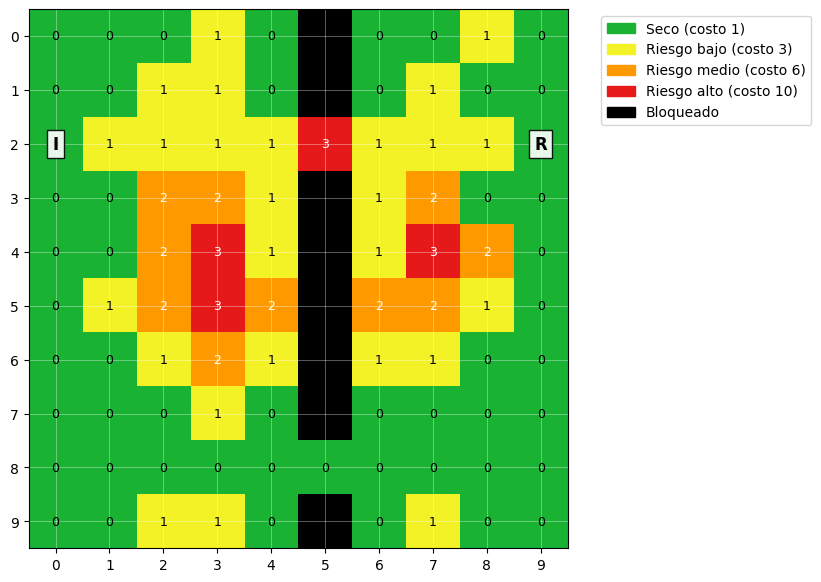

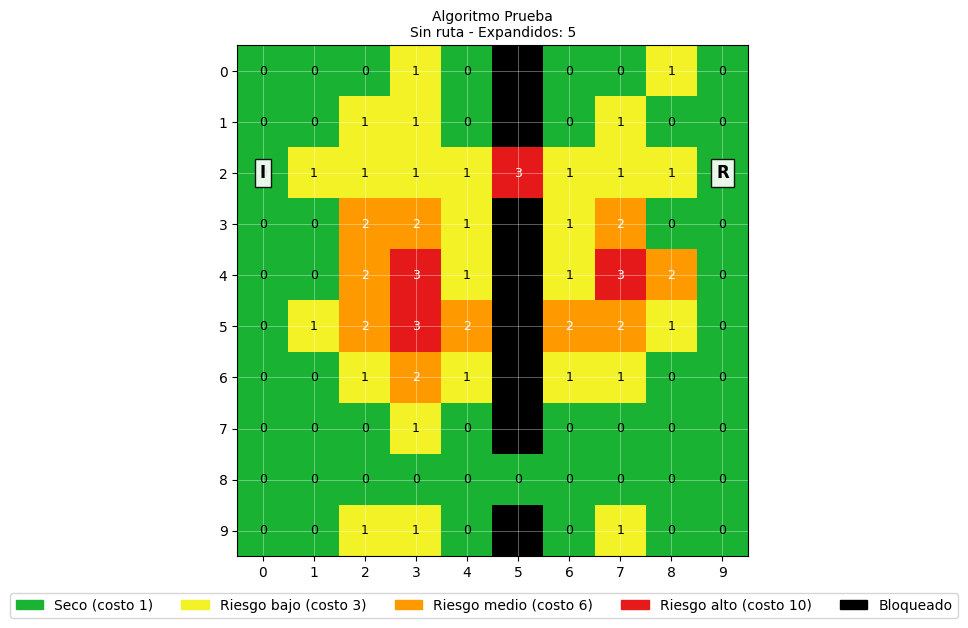

Parte 6: las funciones de visualización no fallan

=== COMPARATIVA VISUAL DE RUTAS ENCONTRADAS ===


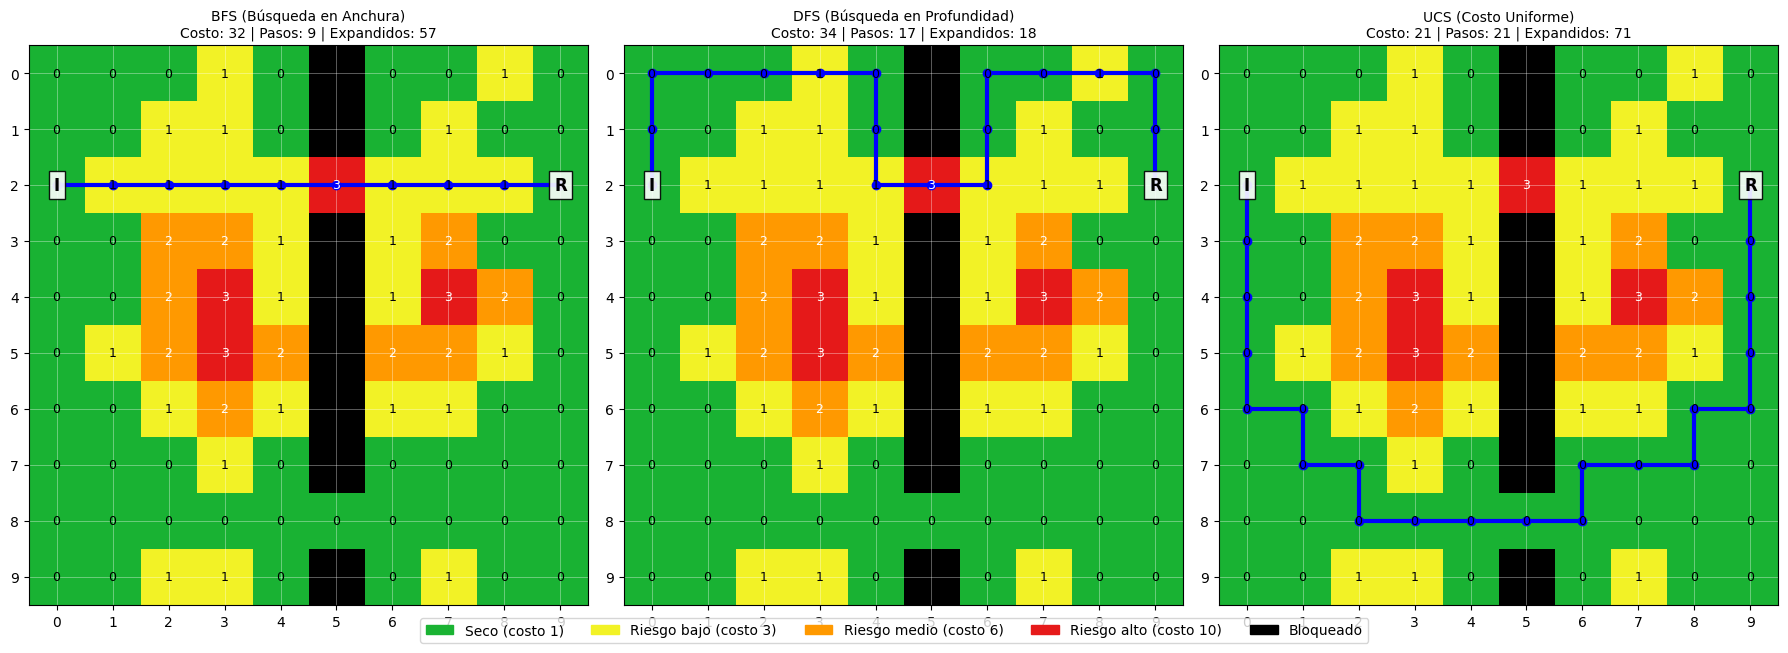

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==========================================
# 1. FUNCIÓN PARA DIBUJAR EL TERRENO
# ==========================================

def dibujar_terreno(mapa, inicio, refugio, ruta=None, titulo="", ax=None):
    """
    Dibuja el mapa de inundación con colores específicos para cada celda,
    muestra los valores de riesgo, las marcas de inicio/refugio y dibuja la ruta si existe.
    """
    # Definimos la paleta de colores requerida
    # BLOQUEADO (-1) = negro, 0 = verde, 1 = amarillo, 2 = naranja, 3 = rojo
    colores_rgb = {
        -1: [0.0, 0.0, 0.0],     # Negro
         0: [0.1, 0.7, 0.2],     # Verde
         1: [0.95, 0.95, 0.15],  # Amarillo
         2: [1.0, 0.6, 0.0],     # Naranja
         3: [0.9, 0.1, 0.1]      # Rojo
    }

    filas, columnas = mapa.shape

    # Creamos una matriz RGB vacía (filas x columnas x 3 canales)
    matriz_colores = np.zeros((filas, columnas, 3))
    for f in range(filas):
        for c in range(columnas):
            valor = mapa[f, c]
            matriz_colores[f, c] = colores_rgb[valor]

    # Si no se provee un ax, creamos una figura propia
    mi_propio_ax = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
        mi_propio_ax = True

    # Mostramos la matriz como imagen.
    # El origen 'upper' garantiza que la fila 0 quede en la parte superior.
    ax.imshow(matriz_colores, origin='upper')

    # Escribimos el nivel de riesgo en las celdas no bloqueadas
    for f in range(filas):
        for c in range(columnas):
            valor = mapa[f, c]
            if valor != BLOQUEADO:
                # Elegimos color del texto para garantizar legibilidad
                color_texto = 'black' if valor in [1, 0] else 'white'
                ax.text(c, f, str(valor), color=color_texto, ha='center', va='center', fontsize=9)

    # Dibujamos las marcas de Inicio (I) y Refugio (R) con recuadro blanco
    propiedades_caja = dict(boxstyle="square,pad=0.3", fc="white", ec="black", lw=1, alpha=0.9)

    # Inicio
    ax.text(inicio[1], inicio[0], "I", color="black", weight="bold",
            ha='center', va='center', fontsize=12, bbox=propiedades_caja)

    # Refugio
    ax.text(refugio[1], refugio[0], "R", color="black", weight="bold",
            ha='center', va='center', fontsize=12, bbox=propiedades_caja)

    # Si hay una ruta válida provista, la dibujamos encima
    if ruta is not None and len(ruta) > 0:
        # Extraemos las coordenadas X (columnas) e Y (filas) de la ruta
        ruta_x = [celda[1] for celda in ruta]
        ruta_y = [celda[0] for celda in ruta]
        ax.plot(ruta_x, ruta_y, color='blue', linewidth=3, marker='o', markersize=6, label="Ruta")

    # Configuración de los ejes para una visualización más limpia
    ax.set_xticks(np.arange(columnas))
    ax.set_yticks(np.arange(filas))
    ax.set_xticklabels(np.arange(columnas))
    ax.set_yticklabels(np.arange(filas))
    ax.grid(color='white', linestyle='-', linewidth=0.5, alpha=0.5)
    ax.set_title(titulo, fontsize=10)

    # Si creamos nuestro propio ax, añadimos la leyenda y mostramos el gráfico
    if mi_propio_ax:
        parches = [
            mpatches.Patch(color=colores_rgb[0], label=f"Seco (costo {COSTOS[0]})"),
            mpatches.Patch(color=colores_rgb[1], label=f"Riesgo bajo (costo {COSTOS[1]})"),
            mpatches.Patch(color=colores_rgb[2], label=f"Riesgo medio (costo {COSTOS[2]})"),
            mpatches.Patch(color=colores_rgb[3], label=f"Riesgo alto (costo {COSTOS[3]})"),
            mpatches.Patch(color=colores_rgb[-1], label="Bloqueado")
        ]
        ax.legend(handles=parches, bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.show()

# ==========================================
# 2. FUNCIÓN PARA COMPARAR VISUALMENTE
# ==========================================

def comparar_visual(mapa, inicio, refugio, resultados):
    """
    Genera una fila de subplots para comparar visualmente las rutas de diferentes algoritmos.
    """
    n_algoritmos = len(resultados)
    fig, ejes = plt.subplots(1, n_algoritmos, figsize=(6 * n_algoritmos, 6), squeeze=False)

    # Iteramos por cada algoritmo en el diccionario de resultados
    for idx, (nombre_alg, datos) in enumerate(resultados.items()):
        ax = ejes[0, idx]
        ruta, costo, expandidos = datos

        if ruta is None:
            titulo_subplot = f"{nombre_alg}\nSin ruta - Expandidos: {expandidos}"
        else:
            pasos = len(ruta) - 1
            titulo_subplot = f"{nombre_alg}\nCosto: {costo} | Pasos: {pasos} | Expandidos: {expandidos}"

        # Dibujamos el terreno con su respectiva ruta
        dibujar_terreno(mapa, inicio, refugio, ruta=ruta, titulo=titulo_subplot, ax=ax)

    # Creamos una única leyenda para toda la figura en la parte superior o inferior
    colores_rgb = {
        -1: [0.0, 0.0, 0.0],
         0: [0.1, 0.7, 0.2],
         1: [0.95, 0.95, 0.15],
         2: [1.0, 0.6, 0.0],
         3: [0.9, 0.1, 0.1]
    }

    parches_unicos = [
        mpatches.Patch(color=colores_rgb[0], label=f"Seco (costo {COSTOS[0]})"),
        mpatches.Patch(color=colores_rgb[1], label=f"Riesgo bajo (costo {COSTOS[1]})"),
        mpatches.Patch(color=colores_rgb[2], label=f"Riesgo medio (costo {COSTOS[2]})"),
        mpatches.Patch(color=colores_rgb[3], label=f"Riesgo alto (costo {COSTOS[3]})"),
        mpatches.Patch(color=colores_rgb[-1], label="Bloqueado")
    ]

    # Posicionamos la leyenda de forma global en la parte inferior
    fig.legend(handles=parches_unicos, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.05))
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. COMPROBACIONES REQUERIDAS (PRUEBAS UNITARIAS)
# ==========================================

try:
    # Comprobación 1: Dibujar terreno sin ruta
    dibujar_terreno(mapa_simulacion, INICIO, REFUGIO, ruta=None)

    # Comprobación 2: Comparar visual con un resultado sin ruta (None, None, 5)
    pruebas_dict = {"Algoritmo Prueba": (None, None, 5)}
    comparar_visual(mapa_simulacion, INICIO, REFUGIO, pruebas_dict)

    print("Parte 6: las funciones de visualización no fallan\n")
except Exception as e:
    print(f"Error detectado durante las pruebas de visualización: {e}")

# ==========================================
# 4. EJECUCIÓN Y COMPARACIÓN LADO A LADO
# ==========================================

# Obtenemos los resultados frescos de la simulación
mapa_actual = crear_mapa_principal()
res_bfs = bfs(mapa_actual, INICIO, REFUGIO)
res_dfs = dfs(mapa_actual, INICIO, REFUGIO)
res_ucs = ucs(mapa_actual, INICIO, REFUGIO)

resultados_simulacion = {
    "BFS (Búsqueda en Anchura)": res_bfs,
    "DFS (Búsqueda en Profundidad)": res_dfs,
    "UCS (Costo Uniforme)": res_ucs
}

# Mostramos la comparación final de forma gráfica
print("=== COMPARATIVA VISUAL DE RUTAS ENCONTRADAS ===")
comparar_visual(mapa_actual, INICIO, REFUGIO, resultados_simulacion)

In [ ]:
def validar_ruta(mapa, ruta, inicio, refugio, costo_reportado=None):
    """
    Valida de forma independiente una ruta propuesta en el mapa de inundación.
    Retorna una tupla: (es_valida, errores, costo_recalculado)
    """
    # Caso inicial: Ruta nula o vacía
    if ruta is None or len(ruta) == 0:
        return (False, ["La ruta está vacía o es None"], None)

    errores = []
    filas, columnas = mapa.shape
    ruta_fuera_de_limites = False
    toca_bloqueado = False

    # a. Verificar límites del mapa para cada celda de forma explícita
    for i, celda in enumerate(ruta):
        f, c = celda
        if not (0 <= f < filas and 0 <= c < columnas):
            ruta_fuera_de_limites = True
            errores.append(f"La celda en la posición {i} {celda} está fuera de los límites del mapa (0-{filas-1}, 0-{columnas-1})")
        else:
            # e. Verificar si la celda es un obstáculo bloqueado
            if mapa[f, c] == BLOQUEADO:
                toca_bloqueado = True
                errores.append(f"La celda en la posición {i} {celda} es una zona BLOQUEADA (#)")

    # b. La primera celda debe ser igual al inicio
    if ruta[0] != inicio:
        errores.append(f"El punto de partida de la ruta {ruta[0]} no coincide con el INICIO esperado {inicio}")

    # c. La última celda debe ser igual al refugio
    if ruta[-1] != refugio:
        errores.append(f"El destino final de la ruta {ruta[-1]} no coincide con el REFUGIO esperado {refugio}")

    # d. Cada par de celdas consecutivas debe tener distancia Manhattan igual a 1
    for i in range(len(ruta) - 1):
        f1, c1 = ruta[i]
        f2, c2 = ruta[i+1]
        distancia = abs(f1 - f2) + abs(c1 - c2)
        if distancia != 1:
            errores.append(f"Salto inválido entre la posición {i} {ruta[i]} y la {i+1} {ruta[i+1]} (Distancia Manhattan: {distancia}, debe ser 1)")

    # Calcular costo recalculado si no hay celdas fuera de límites ni bloqueadas
    costo_recalculado = None
    if not ruta_fuera_de_limites and not toca_bloqueado:
        costo_recalculado = 0
        # La celda de inicio (índice 0) no suma costo
        for i in range(1, len(ruta)):
            f, c = ruta[i]
            valor_celda = mapa[f, c]
            costo_recalculado += COSTOS[valor_celda]

        # f. Si se proporcionó un costo reportado, verificar que coincida
        if costo_reportado is not None:
            if costo_reportado != costo_recalculado:
                errores.append(f"El costo reportado ({costo_reportado}) no coincide con el costo recalculado ({costo_recalculado})")

    # La ruta es válida si no se detectaron errores
    es_valida = (len(errores) == 0)
    return (es_valida, errores, costo_recalculado)


def refugio_es_alcanzable(mapa, inicio, refugio):
    """
    Determina de forma independiente si hay un camino libre desde el inicio al refugio.
    Usa un algoritmo de DFS simplificado y local.
    """
    filas, columnas = mapa.shape
    fi, ci = inicio
    fr, cr = refugio

    # Validaciones iniciales básicas de límites y bloqueos
    if not (0 <= fi < filas and 0 <= ci < columnas) or not (0 <= fr < filas and 0 <= cr < columnas):
        return False
    if mapa[inicio] == BLOQUEADO or mapa[refugio] == BLOQUEADO:
        return False

    # Pila para el recorrido DFS
    pila = [inicio]
    visitados = {inicio}

    while pila:
        actual = pila.pop()
        if actual == refugio:
            return True

        f, col = actual
        # Movimientos ortogonales sencillos sin llamar a obtener_vecinos
        movimientos = [(f-1, col), (f, col+1), (f+1, col), (f, col-1)]

        for nf, nc in movimientos:
            if 0 <= nf < filas and 0 <= nc < columnas:
                if mapa[nf, nc] != BLOQUEADO and (nf, nc) not in visitados:
                    visitados.add((nf, nc))
                    pila.append((nf, nc))

    return False

# ==========================================
# PRUEBAS UNITARIAS DE VALIDACIÓN (ASSERTS)
# ==========================================

mapa_prueba = crear_mapa_principal()

# Obtención limpia de las rutas actuales en variables locales
_r_bfs, _c_bfs, _ = bfs(mapa_prueba, INICIO, REFUGIO)
_r_dfs, _c_dfs, _ = dfs(mapa_prueba, INICIO, REFUGIO)
_r_ucs, _c_ucs, _ = ucs(mapa_prueba, INICIO, REFUGIO)

# a. Validación de rutas de BFS, DFS y UCS en mapa principal
val_bfs, err_bfs, cost_bfs = validar_ruta(mapa_prueba, _r_bfs, INICIO, REFUGIO, _c_bfs)
assert val_bfs is True and err_bfs == [] and cost_bfs == 32

val_dfs, err_dfs, cost_dfs = validar_ruta(mapa_prueba, _r_dfs, INICIO, REFUGIO, _c_dfs)
assert val_dfs is True and err_dfs == [] and cost_dfs == 34

val_ucs, err_ucs, cost_ucs = validar_ruta(mapa_prueba, _r_ucs, INICIO, REFUGIO, _c_ucs)
assert val_ucs is True and err_ucs == [] and cost_ucs == 21

# b. Ruta que no empieza en el inicio
r_sin_inicio = _r_ucs[1:]
val_b, err_b, _ = validar_ruta(mapa_prueba, r_sin_inicio, INICIO, REFUGIO)
assert val_b is False and len(err_b) > 0

# c. Ruta que no termina en el refugio
r_sin_fin = _r_ucs[:-1]
val_c, err_c, _ = validar_ruta(mapa_prueba, r_sin_fin, INICIO, REFUGIO)
assert val_c is False and len(err_c) > 0

# d. Ruta con un salto (distancia Manhattan > 1)
r_salto = [(2, 0), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]
val_d, err_d, _ = validar_ruta(mapa_prueba, r_salto, INICIO, REFUGIO)
assert val_d is False and len(err_d) > 0

# e. Ruta que pasa por una celda bloqueada (1, 5)
r_bloqueada = [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (2, 9)]
val_e, err_e, cost_e = validar_ruta(mapa_prueba, r_bloqueada, INICIO, REFUGIO)
assert val_e is False and len(err_e) > 0 and cost_e is None

# f. Costo reportado incorrecto vs correcto
val_f_inc, err_f_inc, _ = validar_ruta(mapa_prueba, _r_bfs, INICIO, REFUGIO, costo_reportado=31)
assert val_f_inc is False and len(err_f_inc) > 0
val_f_cor, err_f_cor, _ = validar_ruta(mapa_prueba, _r_bfs, INICIO, REFUGIO, costo_reportado=32)
assert val_f_cor is True and err_f_cor == []

# g. Ruta fuera de los límites de forma explícita
r_fuera = [(2, 0), (1, 0), (0, 0), (-1, 0)]
val_g, err_g, cost_g = validar_ruta(mapa_prueba, r_fuera, (2, 0), (-1, 0))
assert val_g is False and len(err_g) > 0 and cost_g is None

# h. Ruta None y ruta vacía []
assert validar_ruta(mapa_prueba, None, INICIO, REFUGIO) == (False, ["La ruta está vacía o es None"], None)
assert validar_ruta(mapa_prueba, [], INICIO, REFUGIO) == (False, ["La ruta está vacía o es None"], None)

# i. refugio_es_alcanzable
# Alcanzable en mapa principal
assert refugio_es_alcanzable(mapa_prueba, INICIO, REFUGIO) is True
# No alcanzable si se rodea el refugio con bloques
mapa_aislado_p = mapa_prueba.copy()
mapa_aislado_p[1, 9] = BLOQUEADO
mapa_aislado_p[3, 9] = BLOQUEADO
mapa_aislado_p[2, 8] = BLOQUEADO
assert refugio_es_alcanzable(mapa_aislado_p, INICIO, REFUGIO) is False
# No alcanzable si el inicio está bloqueado
mapa_bloq_i = mapa_prueba.copy()
mapa_bloq_i[INICIO] = BLOQUEADO
assert refugio_es_alcanzable(mapa_bloq_i, INICIO, REFUGIO) is False

# j. Comprobar que no se modificó el mapa en absoluto
assert np.array_equal(mapa_prueba, crear_mapa_principal())

print("Parte 7: todas las pruebas pasaron\n")

# ==========================================
# IMPRESIÓN DE LA TABLA COMPARATIVA
# ==========================================

# Realizamos la validación y guardamos datos en un diccionario local
resultados_tabla = {
    "BFS": (_r_bfs, _c_bfs),
    "DFS": (_r_dfs, _c_dfs),
    "UCS": (_r_ucs, _c_ucs)
}

print(f"{'Algoritmo':<15} | {'¿Válida?':<10} | {'Costo Reportado':<15} | {'Costo Recalculado':<17}")
print("-" * 65)
for nombre, (r, c) in resultados_tabla.items():
    es_valida, _, costo_recalc = validar_ruta(mapa_prueba, r, INICIO, REFUGIO, c)
    valida_str = "Sí" if es_valida else "No"
    print(f"{nombre:<15} | {valida_str:<10} | {c:<15} | {costo_recalc:<17}")

Parte 7: todas las pruebas pasaron

Algoritmo       | ¿Válida?   | Costo Reportado | Costo Recalculado
-----------------------------------------------------------------
BFS             | Sí         | 32              | 32               
DFS             | Sí         | 34              | 34               
UCS             | Sí         | 21              | 21               


Ejecutando Prueba 1...

--- DATOS DEL ESCENARIO: 1. Ruta disponible ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,1. Ruta disponible,BFS,Sí,Sí,32,9,57
1,1. Ruta disponible,DFS,Sí,Sí,34,17,18
2,1. Ruta disponible,UCS,Sí,Sí,21,21,71


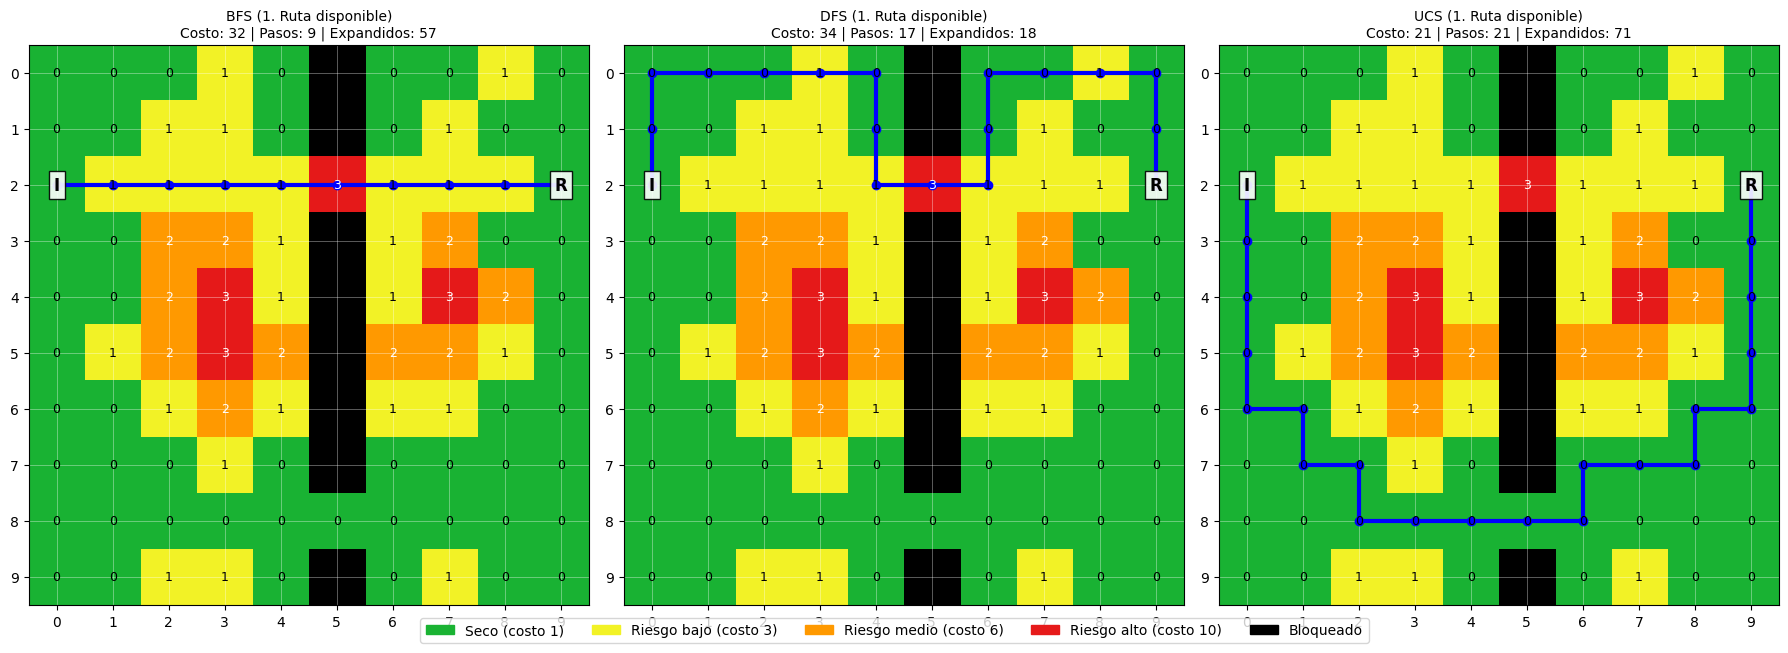

In [ ]:
import pandas as pd

# =========================================================================
# 1. LISTA GLOBAL DE TABLAS
# =========================================================================
TABLAS = []

# =========================================================================
# 2. FUNCIÓN DE EJECUCIÓN DE ESCENARIOS
# =========================================================================
def ejecutar_escenario(nombre, mapa, inicio, refugio, mostrar=True):
    """
    Ejecuta BFS, DFS y UCS sobre el mapa provisto, valida las rutas generadas
    y resume las métricas en un DataFrame de Pandas.
    """
    # Ejecución de los algoritmos
    res_bfs = bfs(mapa, inicio, refugio)
    res_dfs = dfs(mapa, inicio, refugio)
    res_ucs = ucs(mapa, inicio, refugio)

    algoritmos = {
        "BFS": res_bfs,
        "DFS": res_dfs,
        "UCS": res_ucs
    }

    filas = []
    resultados = {}

    for nombre_alg, (ruta, costo, nodos) in algoritmos.items():
        # Almacenamos el resultado en el formato solicitado
        resultados[nombre_alg] = (ruta, costo, nodos)

        # Validación independiente
        if ruta is not None:
            es_valida, errores, costo_recalc = validar_ruta(mapa, ruta, inicio, refugio, costo)
            if not es_valida:
                raise AssertionError(
                    f"Error de validación en Escenario: '{nombre}', Algoritmo: '{nombre_alg}'. "
                    f"Errores detectados: {errores}"
                )
            hay_ruta_str = "Sí"
            valida_str = "Sí"
            pasos = len(ruta) - 1
        else:
            hay_ruta_str = "No"
            valida_str = "N/A"
            costo = None
            pasos = None

        # Construcción de la fila de datos para el DataFrame
        filas.append({
            "Escenario": nombre,
            "Algoritmo": nombre_alg,
            "¿Hay ruta?": hay_ruta_str,
            "¿Válida?": valida_str,
            "Costo": costo,
            "Pasos": pasos,
            "Nodos expandidos": nodos
        })

    # Crear el DataFrame con el orden de columnas solicitado
    df = pd.DataFrame(filas, columns=[
        "Escenario", "Algoritmo", "¿Hay ruta?", "¿Válida?", "Costo", "Pasos", "Nodos expandidos"
    ])

    # Agregar a la lista global
    TABLAS.append(df)

    # Mostrar visualizaciones si se solicita
    if mostrar:
        print(f"\n--- DATOS DEL ESCENARIO: {nombre} ---")
        display(df)
        comparar_visual(mapa, inicio, refugio, {
            f"{nombre_alg} ({nombre})": datos for nombre_alg, datos in resultados.items()
        })

    return df, resultados

# =========================================================================
# 3. PRUEBA 1 – Ruta disponible
# =========================================================================
print("Ejecutando Prueba 1...")
mapa1 = crear_mapa_principal()
df1, res1 = ejecutar_escenario("1. Ruta disponible", mapa1, INICIO, REFUGIO)

# Desestructuración de resultados
ruta_bfs1, costo_bfs1, _ = res1["BFS"]
ruta_dfs1, costo_dfs1, _ = res1["DFS"]
ruta_ucs1, costo_ucs1, _ = res1["UCS"]

# Aserciones para la Prueba 1
assert ruta_bfs1 is not None and ruta_dfs1 is not None and ruta_ucs1 is not None, "Las tres rutas deben existir."
assert costo_bfs1 == 32, f"Costo BFS esperado: 32, obtenido: {costo_bfs1}"
assert costo_dfs1 == 34, f"Costo DFS esperado: 34, obtenido: {costo_dfs1}"
assert costo_ucs1 == 21, f

Ejecutando Prueba 2a...

--- DATOS DEL ESCENARIO: 2a. Se bloquea (8,5) ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,"2a. Se bloquea (8,5)",BFS,Sí,Sí,32,9,57
1,"2a. Se bloquea (8,5)",DFS,Sí,Sí,34,17,18
2,"2a. Se bloquea (8,5)",UCS,Sí,Sí,32,9,64


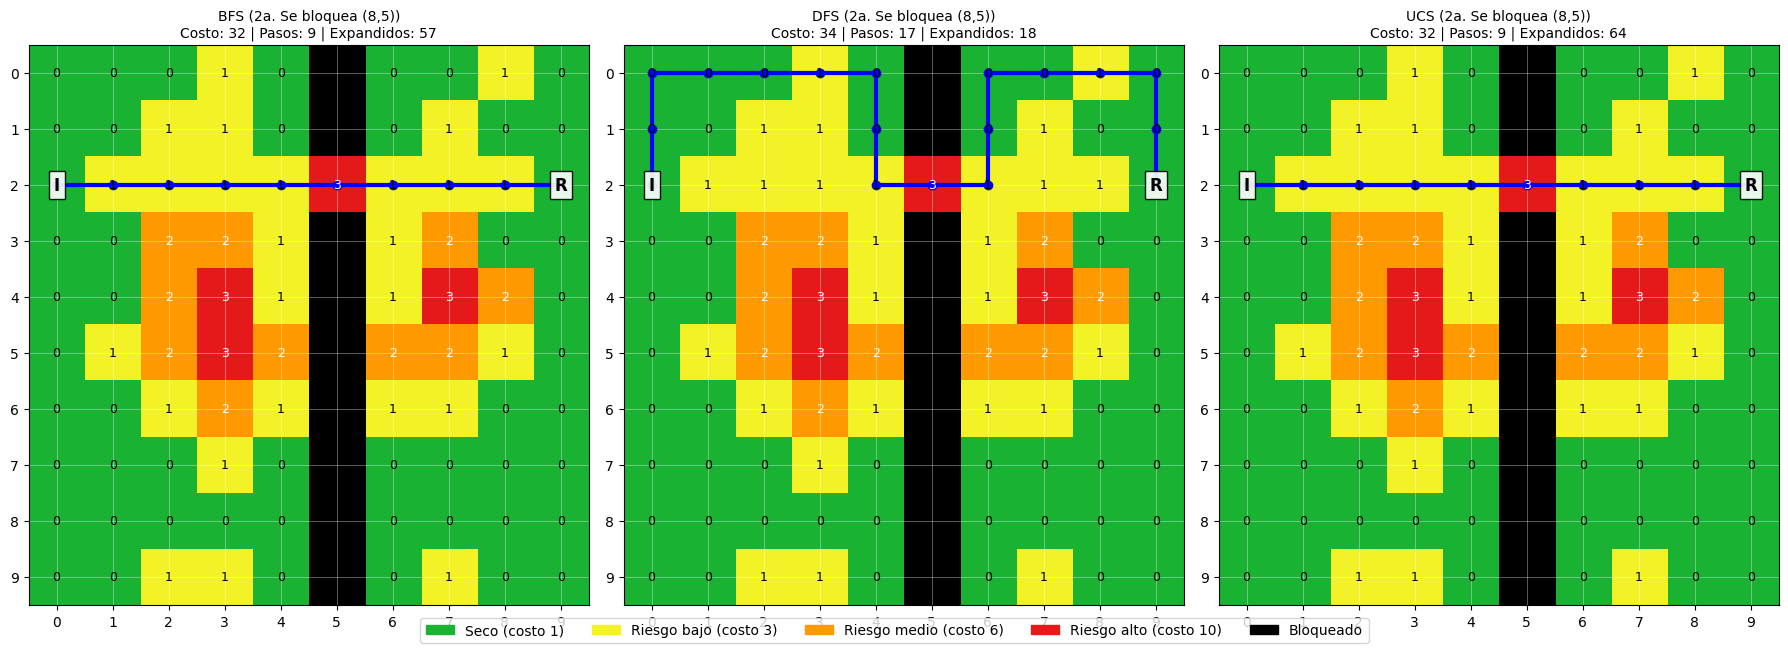


Ejecutando Prueba 2b...

--- DATOS DEL ESCENARIO: 2b. Se bloquea (2,5) ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,"2b. Se bloquea (2,5)",BFS,Sí,Sí,57,21,88
1,"2b. Se bloquea (2,5)",DFS,Sí,Sí,59,29,30
2,"2b. Se bloquea (2,5)",UCS,Sí,Sí,21,21,71


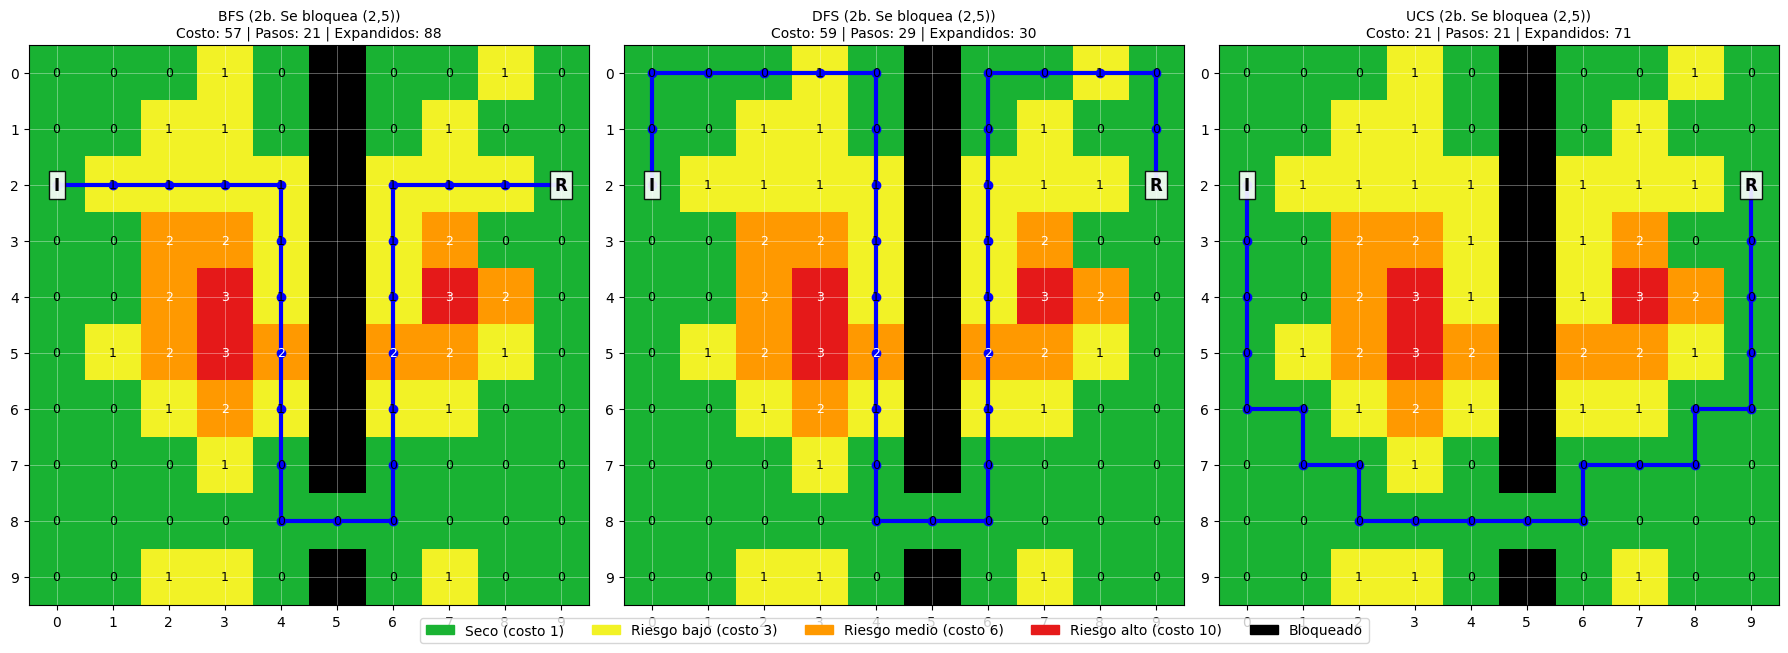


Ejecutando Prueba 3...

--- DATOS DEL ESCENARIO: 3. Refugio inaccesible ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,3. Refugio inaccesible,BFS,No,N/A,None,None,88
1,3. Refugio inaccesible,DFS,No,N/A,None,None,88
2,3. Refugio inaccesible,UCS,No,N/A,None,None,88


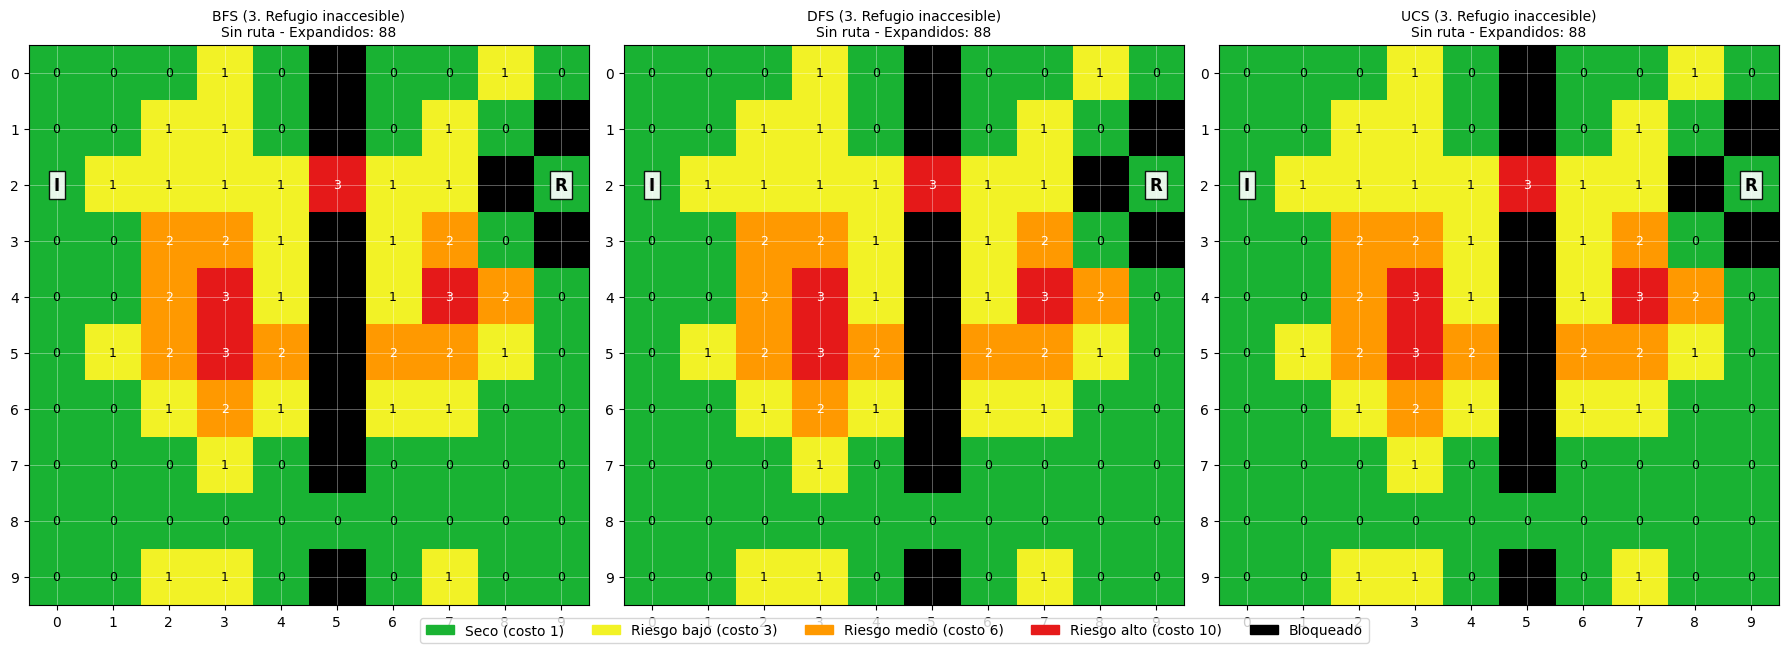


Parte 8: todas las pruebas pasaron


In [ ]:
# Recuperamos la ruta original de UCS obtenida en la Prueba 1
ruta_ucs_original = ruta_ucs1

# =========================================================================
# PRUEBA 2a – Se bloquea una celda de la ruta de UCS
# =========================================================================
print("Ejecutando Prueba 2a...")

# Confirmar que la celda (8, 5) estaba en la ruta original de UCS
assert (8, 5) in ruta_ucs_original, "La celda (8, 5) debería estar en la ruta UCS original."

# Crear copia del mapa y bloquear la celda (8, 5)
mapa2a = crear_mapa_principal()
mapa2a[8, 5] = BLOQUEADO

# Ejecutar el escenario
df2a, res2a = ejecutar_escenario("2a. Se bloquea (8,5)", mapa2a, INICIO, REFUGIO)

# Desestructurar resultados de la prueba 2a
ruta_bfs2a, costo_bfs2a, _ = res2a["BFS"]
ruta_dfs2a, costo_dfs2a, _ = res2a["DFS"]
ruta_ucs2a, costo_ucs2a, _ = res2a["UCS"]

# Aserciones para Prueba 2a
assert ruta_ucs2a is not None, "La nueva ruta de UCS debería existir."
assert (8, 5) not in ruta_ucs2a, "La nueva ruta de UCS no debería contener la celda bloqueada (8, 5)."
assert (2, 5) in ruta_ucs2a, "La nueva ruta de UCS debería contener la celda (2, 5) al verse forzada a subir."
assert costo_ucs2a > 21, f"El costo de UCS ({costo_ucs2a}) debería ser estrictamente mayor que 21."
assert costo_bfs2a == 32, f"El costo de BFS debería seguir siendo 32, se obtuvo: {costo_bfs2a}"
assert costo_dfs2a == 34, f"El costo de DFS debería seguir siendo 34, se obtuvo: {costo_dfs2a}"

# =========================================================================
# PRUEBA 2b – Se bloquea una celda de las rutas de BFS y DFS
# =========================================================================
print("\nEjecutando Prueba 2b...")

# Crear copia del mapa y bloquear la celda (2, 5)
mapa2b = crear_mapa_principal()
mapa2b[2, 5] = BLOQUEADO

# Ejecutar el escenario
df2b, res2b = ejecutar_escenario("2b. Se bloquea (2,5)", mapa2b, INICIO, REFUGIO)

# Desestructurar resultados de la prueba 2b
ruta_bfs2b, costo_bfs2b, _ = res2b["BFS"]
ruta_dfs2b, costo_dfs2b, _ = res2b["DFS"]
ruta_ucs2b, costo_ucs2b, _ = res2b["UCS"]

# Aserciones para Prueba 2b
assert ruta_bfs2b is not None and ruta_dfs2b is not None and ruta_ucs2b is not None, "Las rutas de BFS, DFS y UCS deben existir."
assert (2, 5) not in ruta_bfs2b, "La ruta de BFS no debe contener (2, 5)."
assert (2, 5) not in ruta_dfs2b, "La ruta de DFS no debe contener (2, 5)."
assert (2, 5) not in ruta_ucs2b, "La ruta de UCS no debe contener (2, 5)."

pasos_bfs2b = len(ruta_bfs2b) - 1
assert pasos_bfs2b == 21, f"BFS debería tener exactamente 21 pasos, se obtuvieron: {pasos_bfs2b}"
assert costo_ucs2b == 21, f"UCS debería mantener un costo óptimo de 21, se obtuvo: {costo_ucs2b}"

# =========================================================================
# PRUEBA 3 – Refugio inaccesible
# =========================================================================
print("\nEjecutando Prueba 3...")

# Crear copia del mapa y aislar por completo el refugio
mapa3 = crear_mapa_principal()
mapa3[1, 9] = BLOQUEADO
mapa3[3, 9] = BLOQUEADO
mapa3[2, 8] = BLOQUEADO

# Ejecutar escenario sin que lance excepciones
df3, res3 = ejecutar_escenario("3. Refugio inaccesible", mapa3, INICIO, REFUGIO)

# Desestructurar resultados de la prueba 3
ruta_bfs3, costo_bfs3, nodos_bfs3 = res3["BFS"]
ruta_dfs3, costo_dfs3, nodos_dfs3 = res3["DFS"]
ruta_ucs3, costo_ucs3, nodos_ucs3 = res3["UCS"]

# Aserciones para Prueba 3
assert ruta_bfs3 is None and costo_bfs3 is None, "BFS no debería encontrar ruta."
assert ruta_dfs3 is None and costo_dfs3 is None, "DFS no debería encontrar ruta."
assert ruta_ucs3 is None and costo_ucs3 is None, "UCS no debería encontrar ruta."

# Validar alcanzabilidad
recanzable = refugio_es_alcanzable(mapa3, INICIO, REFUGIO)
assert recanzable is False, "El refugio no debería ser alcanzable en mapa3."

# Validar nodos expandidos (deben ser idénticos e iguales a 88 celdas transitables accesibles)
assert nodos_bfs3 == 88, f"Nodos expandidos BFS esperados: 88, obtenidos: {nodos_bfs3}"
assert nodos_dfs3 == 88, f"Nodos expandidos DFS esperados: 88, obtenidos: {nodos_dfs3}"
assert nodos_ucs3 == 88, f"Nodos expandidos UCS esperados: 88, obtenidos: {nodos_ucs3}"

# Validar la ruta nula de forma directa con la función de validación independiente
es_valida_null, _, _ = validar_ruta(mapa3, None, INICIO, REFUGIO)
assert es_valida_null is False, "validar_ruta con None debe retornar False."

# Finalización exitosa
print("\nParte 8: todas las pruebas pasaron")

Ejecutando Prueba 4...
La ruta antigua de UCS ahora costaría: 39

--- DATOS DEL ESCENARIO: 4. Sube el riesgo del corredor sur ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,4. Sube el riesgo del corredor sur,BFS,Sí,Sí,32,9,57
1,4. Sube el riesgo del corredor sur,DFS,Sí,Sí,34,17,18
2,4. Sube el riesgo del corredor sur,UCS,Sí,Sí,32,9,69


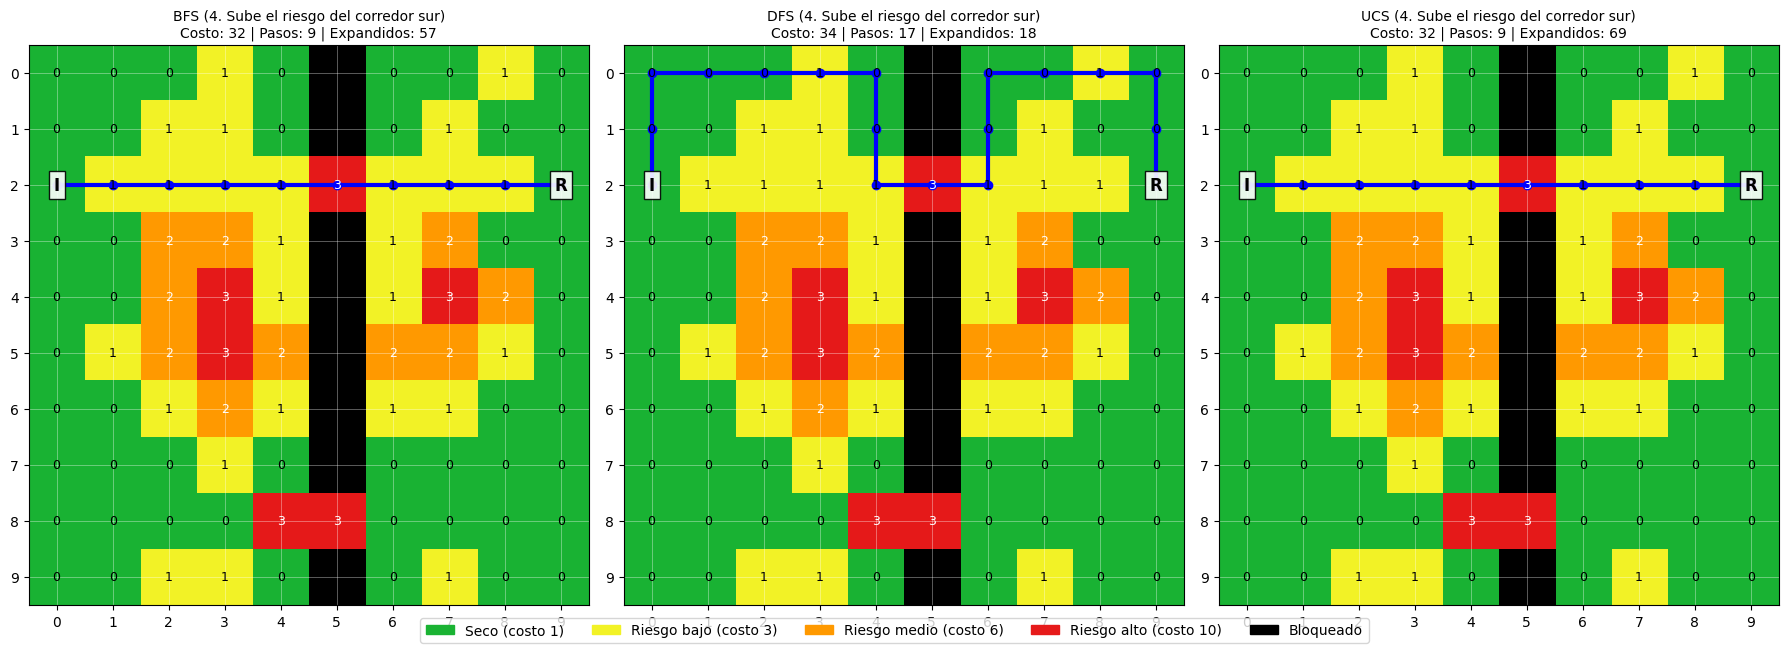


Parte 9a (prueba 4): los assert pasaron


In [ ]:
# =========================================================================
# PRUEBA 4 – Se modifica el riesgo de una región (Corredor Sur)
# =========================================================================
print("Ejecutando Prueba 4...")

# 1. Crear el mapa específico para el escenario 4
mapa4 = crear_mapa_principal()
mapa4[8, 4] = RIESGO_ALTO  # Sube riesgo de 0 a 3
mapa4[8, 5] = RIESGO_ALTO  # Sube riesgo de 0 a 3

# 2. Confirmar mediante aserciones los valores en el mapa original y en la ruta original de UCS
mapa_origen_check = crear_mapa_principal()
assert mapa_origen_check[8, 4] == SECO, "En el mapa original la celda (8, 4) debe ser seca (0)"
assert mapa_origen_check[8, 5] == SECO, "En el mapa original la celda (8, 5) debe ser seca (0)"
assert (8, 4) in ruta_ucs_original, "La celda (8, 4) debería pertenecer a la ruta UCS original"
assert (8, 5) in ruta_ucs_original, "La celda (8, 5) debería pertenecer a la ruta UCS original"

# 3. Evaluar la ruta de UCS original sobre el nuevo mapa de riesgo
es_valida_antigua, errores_antigua, costo_recalc_antiguo = validar_ruta(mapa4, ruta_ucs_original, INICIO, REFUGIO)
assert es_valida_antigua is True, f"La ruta antigua debería seguir siendo espacialmente válida. Errores: {errores_antigua}"
assert costo_recalc_antiguo == 39, f"El costo recalculado debería ser exactamente 39, pero dio {costo_recalc_antiguo}"
print(f"La ruta antigua de UCS ahora costaría: {costo_recalc_antiguo}")

# 4. Ejecutar el escenario formalmente
df4, res4 = ejecutar_escenario("4. Sube el riesgo del corredor sur", mapa4, INICIO, REFUGIO)

# Desestructurar resultados del escenario 4
ruta_bfs4, costo_bfs4, nodos_bfs4 = res4["BFS"]
ruta_dfs4, costo_dfs4, nodos_dfs4 = res4["DFS"]
ruta_ucs4, costo_ucs4, nodos_ucs4 = res4["UCS"]

# 5. Aserciones sobre UCS (Debe esquivar la zona de alto costo y subir por la fila 2)
assert ruta_ucs4 is not None, "Debe existir una ruta para UCS"
assert (8, 5) not in ruta_ucs4, "La nueva ruta óptima de UCS debe esquivar la celda costosa (8, 5)"
assert (2, 5) in ruta_ucs4, "La nueva ruta de UCS debe cruzar por el paso central (2, 5)"
assert costo_ucs4 == 32, f"El nuevo costo óptimo de UCS debe ser exactamente 32, obtenido: {costo_ucs4}"

# 6. Aserciones sobre BFS y DFS (No consideran costos, así que su comportamiento espacial y de expansión debe ser idéntico)
# Obtenemos los resultados puros sobre el mapa original
ruta_bfs_orig, costo_bfs_orig, nodos_bfs_orig = bfs(mapa_origen_check, INICIO, REFUGIO)
ruta_dfs_orig, costo_dfs_orig, nodos_dfs_orig = dfs(mapa_origen_check, INICIO, REFUGIO)

# BFS debe ser idéntico en ruta y nodos expandidos
assert ruta_bfs4 == ruta_bfs_orig, "La ruta espacial de BFS no debería cambiar por modificaciones de costos"
assert nodos_bfs4 == nodos_bfs_orig, "Los nodos expandidos por BFS deben seguir siendo los mismos"
assert costo_bfs4 == 32, f"El costo de la ruta de BFS evaluada en mapa4 debe ser 32, obtenido: {costo_bfs4}"

# DFS debe ser idéntico en ruta y nodos expandidos
assert ruta_dfs4 == ruta_dfs_orig, "La ruta espacial de DFS no debería cambiar por modificaciones de costos"
assert nodos_dfs4 == nodos_dfs_orig, "Los nodos expandidos por DFS deben seguir siendo los mismos"
assert costo_dfs4 == 34, f"El costo de la ruta de DFS evaluada en mapa4 debe ser 34, obtenido: {costo_dfs4}"

# 7. Confirmación final de la prueba
print("\nParte 9a (prueba 4): los assert pasaron")

Ejecutando Prueba 5...

--- DATOS DEL ESCENARIO: 5. El camino corto no es el mejor ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,5. El camino corto no es el mejor,BFS,Sí,Sí,31,4,8
1,5. El camino corto no es el mejor,DFS,Sí,Sí,31,4,5
2,5. El camino corto no es el mejor,UCS,Sí,Sí,8,8,9


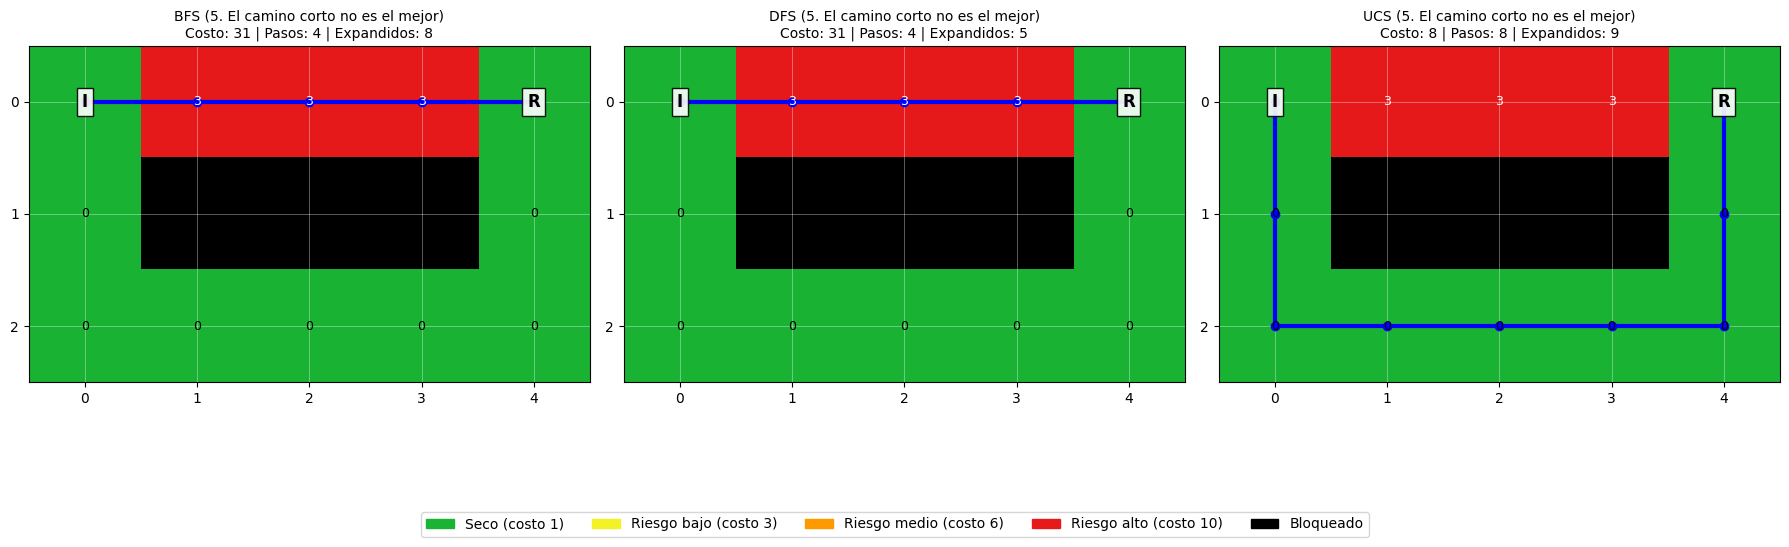


Ruta más corta (BFS): 4 pasos, costo 31.
Ruta más segura (UCS): 8 pasos, costo 8.
El sistema elige la de menor costo total: la de UCS con 8 pasos y costo 8 debido al alto riesgo inundado del corredor directo.

Ejecutando Prueba 5b...

--- DATOS DEL ESCENARIO: 5b. Si el riesgo no pesara (todos los costos = 1) ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,5b. Si el riesgo no pesara (todos los costos = 1),BFS,Sí,Sí,4,4,8
1,5b. Si el riesgo no pesara (todos los costos = 1),DFS,Sí,Sí,4,4,5
2,5b. Si el riesgo no pesara (todos los costos = 1),UCS,Sí,Sí,4,4,8


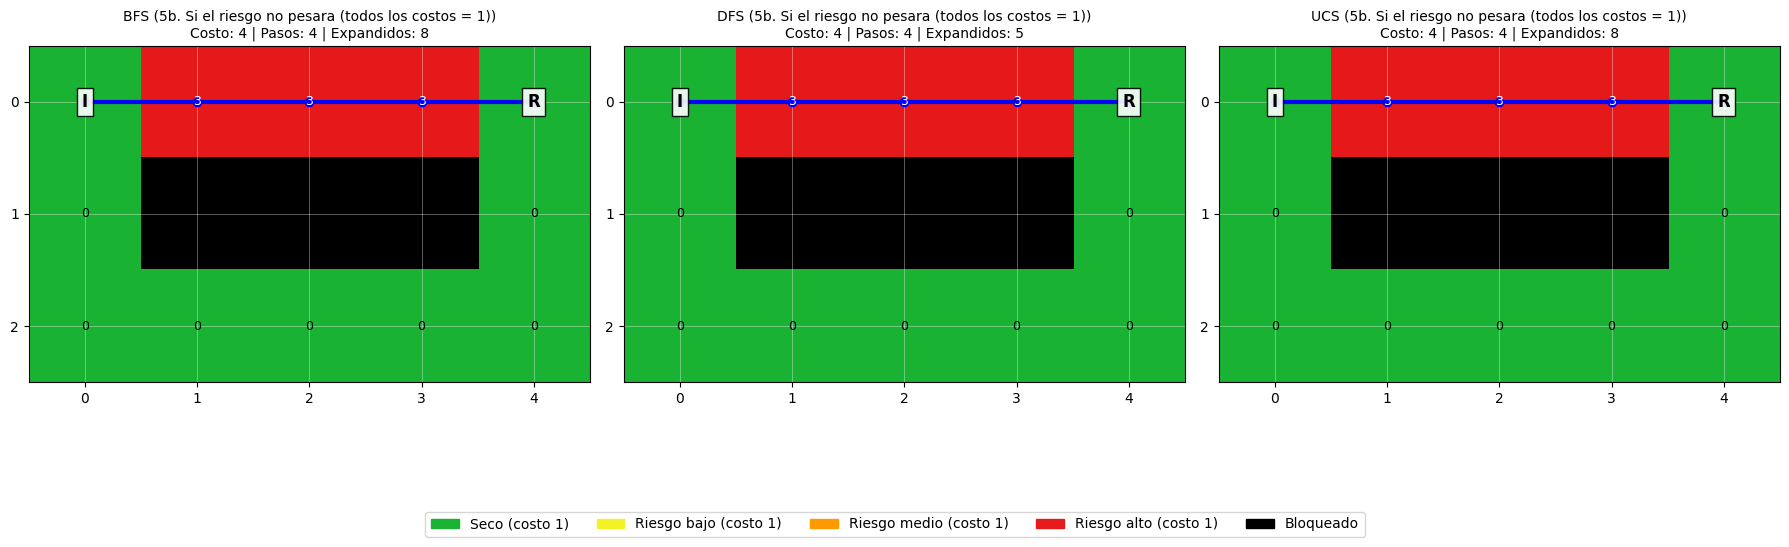


Explicación: Cuando todas las superficies cuestan lo mismo, UCS ignora la profundidad del agua
y optimiza únicamente en distancia. Esto demuestra que es el peso del riesgo asignado
lo que realmente altera la toma de decisiones hacia caminos más seguros en lugar de los más cortos.

Parte 9: todas las pruebas pasaron


In [ ]:
import numpy as np

# =========================================================================
# 1. DEFINICIÓN DEL MAPA TRAMPA Y CONSTANTES DE PRUEBA 5
# =========================================================================
def crear_mapa_trampa():
    """
    Crea y devuelve un mapa NumPy de 3x5 diseñado para forzar un dilema entre
    la ruta más corta en pasos (corredor con riesgo alto) y la más larga pero segura.
    """
    mapa_lista = [
        [ 0,  3,  3,  3,  0],
        [ 0, -1, -1, -1,  0],
        [ 0,  0,  0,  0,  0]
    ]
    return np.array(mapa_lista)

INICIO5 = (0, 0)
REFUGIO5 = (0, 4)

# =========================================================================
# 2. EJECUCIÓN DE LA PRUEBA 5 – El camino más corto deja de ser conveniente
# =========================================================================
print("Ejecutando Prueba 5...")
mapa_trampa = crear_mapa_trampa()
df5, res5 = ejecutar_escenario("5. El camino corto no es el mejor", mapa_trampa, INICIO5, REFUGIO5)

# Desestructuración de resultados de la Prueba 5
ruta_bfs5, costo_bfs5, nodos_bfs5 = res5["BFS"]
ruta_dfs5, costo_dfs5, nodos_dfs5 = res5["DFS"]
ruta_ucs5, costo_ucs5, nodos_ucs5 = res5["UCS"]

# Definición exacta de las rutas esperadas para validación por assert
ruta_bfs_esperada = [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4)]
ruta_ucs_esperada = [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (1, 4), (0, 4)]

# Aserciones de la Prueba 5
assert ruta_bfs5 == ruta_bfs_esperada, f"Ruta BFS esperada {ruta_bfs_esperada}, obtenida: {ruta_bfs5}"
assert costo_bfs5 == 31, f"Costo BFS esperado: 31, obtenido: {costo_bfs5}"
assert len(ruta_bfs5) - 1 == 4, f"Pasos BFS esperados: 4, obtenidos: {len(ruta_bfs5) - 1}"

assert ruta_ucs5 == ruta_ucs_esperada, f"Ruta UCS esperada {ruta_ucs_esperada}, obtenida: {ruta_ucs5}"
assert costo_ucs5 == 8, f"Costo UCS esperado: 8, obtenido: {costo_ucs5}"
assert len(ruta_ucs5) - 1 == 8, f"Pasos UCS esperados: 8, obtenidos: {len(ruta_ucs5) - 1}"

assert costo_ucs5 < costo_bfs5, "El costo de UCS debe ser menor al de BFS"
assert (len(ruta_ucs5) - 1) > (len(ruta_bfs5) - 1), "La ruta de UCS debe tener más pasos que la de BFS"
assert ruta_dfs5 is not None, "La ruta de DFS debe existir"

# Validación del coste de la ruta de DFS
es_val_dfs5, _, _ = validar_ruta(mapa_trampa, ruta_dfs5, INICIO5, REFUGIO5)
assert es_val_dfs5 is True, "La ruta de DFS obtenida debe ser espacialmente válida"
assert nodos_bfs5 == 8, f"Los nodos expandidos de BFS esperados son 8, obtenidos: {nodos_bfs5}"

# =========================================================================
# 3. EXPLICACIÓN DINÁMICA CON VALORES REALES
# =========================================================================
pasos_bfs = len(ruta_bfs5) - 1
pasos_ucs = len(ruta_ucs5) - 1
print(f"\nRuta más corta (BFS): {pasos_bfs} pasos, costo {costo_bfs5}.")
print(f"Ruta más segura (UCS): {pasos_ucs} pasos, costo {costo_ucs5}.")
print(f"El sistema elige la de menor costo total: la de UCS con {pasos_ucs} pasos y costo {costo_ucs5} debido al alto riesgo inundado del corredor directo.\n")

# =========================================================================
# 4. PRUEBA 5b – Sensibilidad al costo del riesgo
# =========================================================================
print("Ejecutando Prueba 5b...")
costos_originales = COSTOS.copy()

try:
    # Modificar el diccionario global en su lugar para anular el impacto del riesgo
    COSTOS.update({0: 1, 1: 1, 2: 1, 3: 1})

    # Ejecutar el escenario con los costos modificados
    df5b, res5b = ejecutar_escenario("5b. Si el riesgo no pesara (todos los costos = 1)", mapa_trampa, INICIO5, REFUGIO5)

    ruta_bfs5b, costo_bfs5b, _ = res5b["BFS"]
    ruta_ucs5b, costo_ucs5b, _ = res5b["UCS"]

    # Comprobaciones de sensibilidad dentro del try
    assert ruta_ucs5b == ruta_bfs5b, "Con costo plano (todos = 1), UCS debería elegir la misma ruta corta que BFS"
    assert costo_ucs5b == 4, f"El costo de UCS con costos planos debería ser de 4, obtenido: {costo_ucs5b}"

finally:
    # Restauración robusta del diccionario global independientemente del resultado del try
    COSTOS.clear()
    COSTOS.update(costos_originales)

# Asegurar que los costos volvieron a su estado original después del bloque try/finally
assert COSTOS == {0: 1, 1: 3, 2: 6, 3: 10}, f"Error al restaurar los costos globales. Obtenidos: {COSTOS}"

print("\nExplicación: Cuando todas las superficies cuestan lo mismo, UCS ignora la profundidad del agua")
print("y optimiza únicamente en distancia. Esto demuestra que es el peso del riesgo asignado")
print("lo que realmente altera la toma de decisiones hacia caminos más seguros en lugar de los más cortos.")

# =========================================================================
# 5. CONFIRMACIÓN FINAL
# =========================================================================
print("\nParte 9: todas las pruebas pasaron")

In [ ]:
import numpy as np

# =========================================================================
# 1. MÉTODO DE REFERENCIA INDEPENDIENTE (ESTILO BELLMAN-FORD)
# =========================================================================
def costo_optimo_referencia(mapa, inicio, refugio, costos=None):
    """
    Calcula el costo mínimo para llegar de inicio a refugio usando relajación repetida
    sin depender de colas de prioridad (heapq), pilas ni estructuras de búsqueda.
    """
    if mapa[inicio] == BLOQUEADO:
        return None

    if costos is None:
        costos = COSTOS

    filas, columnas = mapa.shape
    # Matriz de distancias inicializada con infinito
    distancia = np.full((filas, columnas), np.inf)
    distancia[inicio] = 0.0

    # Relajación repetida
    cambio = True
    while cambio:
        cambio = False
        for f in range(filas):
            for c in range(columnas):
                if mapa[f, c] == BLOQUEADO or distancia[f, c] == np.inf:
                    continue

                # Revisar vecinos de (f, c) en las 4 direcciones
                for df, dc in [(-1, 0), (0, 1), (1, 0), (0, -1)]:
                    nf, nc = f + df, c + dc
                    if 0 <= nf < filas and 0 <= nc < columnas:
                        if mapa[nf, nc] != BLOQUEADO:
                            # El costo de entrar a la celda vecina es costos[nivel]
                            costo_entrada = costos[mapa[nf, nc]]
                            nuevo_costo = distancia[f, c] + costo_entrada
                            if nuevo_costo < distancia[nf, nc]:
                                distancia[nf, nc] = nuevo_costo
                                cambio = True

    costo_final = distancia[refugio]
    return int(costo_final) if costo_final != np.inf else None

# =========================================================================
# 2. GENERADOR DE MAPAS ALEATORIOS
# =========================================================================
def generar_mapa_aleatorio(rng):
    """
    Genera dimensiones, probabilidad de bloqueo, niveles de riesgo inundado
    e inicio/refugio secos al azar usando un generador NumPy RNG.
    """
    filas = rng.integers(4, 11)
    columnas = rng.integers(4, 11)
    prob_bloqueo = rng.uniform(0.10, 0.45)

    # Rellenar con BLOQUEADO (-1) o niveles transitables (0, 1, 2, 3)
    mapa = np.zeros((filas, columnas), dtype=int)
    for f in range(filas):
        for c in range(columnas):
            if rng.random() < prob_bloqueo:
                mapa[f, c] = BLOQUEADO
            else:
                # Niveles con probabilidades 0.4, 0.3, 0.2, 0.1
                mapa[f, c] = rng.choice([0, 1, 2, 3], p=[0.4, 0.3, 0.2, 0.1])

    # Seleccionar inicio y refugio distintos al azar
    posiciones_posibles = [(f, c) for f in range(filas) for c in range(columnas)]
    inicio, refugio = rng.choice(posiciones_posibles, size=2, replace=False)

    # Forzar que el inicio y refugio no estén bloqueados (nivel 0)
    mapa[tuple(inicio)] = 0
    mapa[tuple(refugio)] = 0

    return mapa, tuple(inicio), tuple(refugio)

# =========================================================================
# 3. VERIFICADOR CRUZADO DE ALGORITMOS
# =========================================================================
def verificar_mapa(mapa, inicio, refugio, ucs_func=ucs):
    """
    Verifica BFS, DFS y UCS sobre una copia del mapa contra el resultado del
    método independiente de referencia y propiedades teóricas fundamentales.
    """
    errores = []
    mapa_copia = mapa.copy()

    # Ejecución fresca de los algoritmos en estudio
    r_bfs, c_bfs, _ = bfs(mapa_copia, inicio, refugio)
    r_dfs, c_dfs, _ = dfs(mapa_copia, inicio, refugio)
    r_ucs, c_ucs, _ = ucs_func(mapa_copia, inicio, refugio)

    # a. Verificar que el mapa original no se haya modificado
    if not np.array_equal(mapa, mapa_copia):
        errores.append("El mapa original fue modificado por alguno de los algoritmos.")

    alcanzable = refugio_es_alcanzable(mapa, inicio, refugio)
    costo_ref = costo_optimo_referencia(mapa, inicio, refugio)

    # b. Caso de No Alcanzabilidad
    if not alcanzable:
        if r_bfs is not None:
            errores.append("BFS: Devolvió ruta cuando el refugio no es alcanzable.")
        if r_dfs is not None:
            errores.append("DFS: Devolvió ruta cuando el refugio no es alcanzable.")
        if r_ucs is not None:
            errores.append("UCS: Devolvió ruta cuando el refugio no es alcanzable.")
        if costo_ref is not None:
            errores.append(f"Costo de referencia: Es {costo_ref} en lugar de None para mapa inalcanzable.")

    # c-e. Caso de Alcanzabilidad
    else:
        # Verificar BFS
        val_bfs, err_bfs, _ = validar_ruta(mapa, r_bfs, inicio, refugio, c_bfs)
        if not val_bfs:
            errores.append(f"BFS: Ruta inválida detectada por validar_ruta. Errores: {err_bfs}")
        elif len(set(r_bfs)) != len(r_bfs):
            errores.append("BFS: La ruta contiene ciclos/celdas repetidas.")

        # Verificar DFS
        val_dfs, err_dfs, _ = validar_ruta(mapa, r_dfs, inicio, refugio, c_dfs)
        if not val_dfs:
            errores.append(f"DFS: Ruta inválida detectada por validar_ruta. Errores: {err_dfs}")
        elif len(set(r_dfs)) != len(r_dfs):
            errores.append("DFS: La ruta contiene ciclos/celdas repetidas.")

        # Verificar UCS
        val_ucs, err_ucs, _ = validar_ruta(mapa, r_ucs, inicio, refugio, c_ucs)
        if not val_ucs:
            errores.append(f"UCS: Ruta inválida detectada por validar_ruta. Errores: {err_ucs}")
        elif len(set(r_ucs)) != len(r_ucs):
            errores.append("UCS: La ruta contiene ciclos/celdas repetidas.")

        # d. UCS optimiza el costo
        if val_ucs and val_bfs and val_dfs:
            if c_ucs != costo_ref:
                errores.append(f"UCS: El costo reportado ({c_ucs}) difiere del óptimo de referencia ({costo_ref}).")
            if c_ucs > c_bfs:
                errores.append(f"UCS: Costo ({c_ucs}) es mayor al de BFS ({c_bfs}).")
            if c_ucs > c_dfs:
                errores.append(f"UCS: Costo ({c_ucs}) es mayor al de DFS ({c_dfs}).")

        # e. BFS optimiza cantidad de pasos (costos planos = 1)
        if val_bfs and val_dfs and val_ucs:
            pasos_bfs = len(r_bfs) - 1
            pasos_dfs = len(r_dfs) - 1
            pasos_ucs = len(r_ucs) - 1

            pasos_ref_cortos = costo_optimo_referencia(mapa, inicio, refugio, costos={0:1, 1:1, 2:1, 3:1})
            if pasos_bfs != pasos_ref_cortos:
                errores.append(f"BFS: Pasos ({pasos_bfs}) no coincide con la distancia de referencia mínima ({pasos_ref_cortos}).")
            if pasos_bfs > pasos_dfs:
                errores.append(f"BFS: Encontró una ruta de {pasos_bfs} pasos, mayor que la de DFS ({pasos_dfs}).")
            if pasos_bfs > pasos_ucs:
                errores.append(f"BFS: Encontró una ruta de {pasos_bfs} pasos, mayor que la de UCS ({pasos_ucs}).")

    return errores

# =========================================================================
# 4. EJECUCIÓN DEL BUCLE DE EVALUACIÓN (500 MAPAS ALEATORIOS)
# =========================================================================
rng = np.random.default_rng(2024)

total_mapas = 500
alcanzables = 0
no_alcanzables = 0
mapas_con_errores = 0

historial_errores = []

for i in range(total_mapas):
    m_rand, ini_rand, ref_rand = generar_mapa_aleatorio(rng)

    # Clasificar alcanzabilidad
    if refugio_es_alcanzable(m_rand, ini_rand, ref_rand):
        alcanzables += 1
    else:
        no_alcanzables += 1

    # Verificar
    errs = verificar_mapa(m_rand, ini_rand, ref_rand)
    if len(errs) > 0:
        mapas_con_errores += 1
        historial_errores.append((m_rand, ini_rand, ref_rand, errs))

# Imprimir estadísticas
print(f"=== RESULTADO DE LAS PRUEBAS ALEATORIAS ===")
print(f"Total de mapas analizados: {total_mapas}")
print(f"Mapas con refugio alcanzable: {alcanzables}")
print(f"Mapas con refugio inalcanzable: {no_alcanzables}")
print(f"Cantidad de mapas con algún error: {mapas_con_errores}")

# Si hubo errores, imprimir los 3 primeros antes de fallar el assert
if mapas_con_errores > 0:
    print("\n--- DETALLE DE LOS PRIMEROS ERRORES DETECTADOS ---")
    for idx, (m, ini, ref, errs) in enumerate(historial_errores[:3]):
        print(f"\nError #{idx+1} en mapa de tamaño {m.shape} con inicio {ini} y refugio {ref}:")
        print(f"Mapa:\n{m}")
        print(f"Errores: {errs}")

# 5. ASERCIÓN FINAL
assert mapas_con_errores == 0, f"¡Se detectaron {mapas_con_errores} mapas con errores en las búsquedas!"

print("\nParte 10a: los 500 mapas aleatorios pasaron todas las comprobaciones")

=== RESULTADO DE LAS PRUEBAS ALEATORIAS ===
Total de mapas analizados: 500
Mapas con refugio alcanzable: 421
Mapas con refugio inalcanzable: 79
Cantidad de mapas con algún error: 0

Parte 10a: los 500 mapas aleatorios pasaron todas las comprobaciones


=== VERIFICACIÓN DE UCS DEFECTUOSO ===
Mapas en los que se detectaron fallas: 33 de 500

Errores reportados en el primer mapa detectado como defectuoso:
 - UCS: El costo reportado (27) difiere del óptimo de referencia (24).
 - UCS: Costo (27) es mayor al de BFS (24).

Comparación visual para el mapa de tamaño (4, 9) con inicio (np.int64(0), np.int64(7)) y refugio (np.int64(3), np.int64(1)):


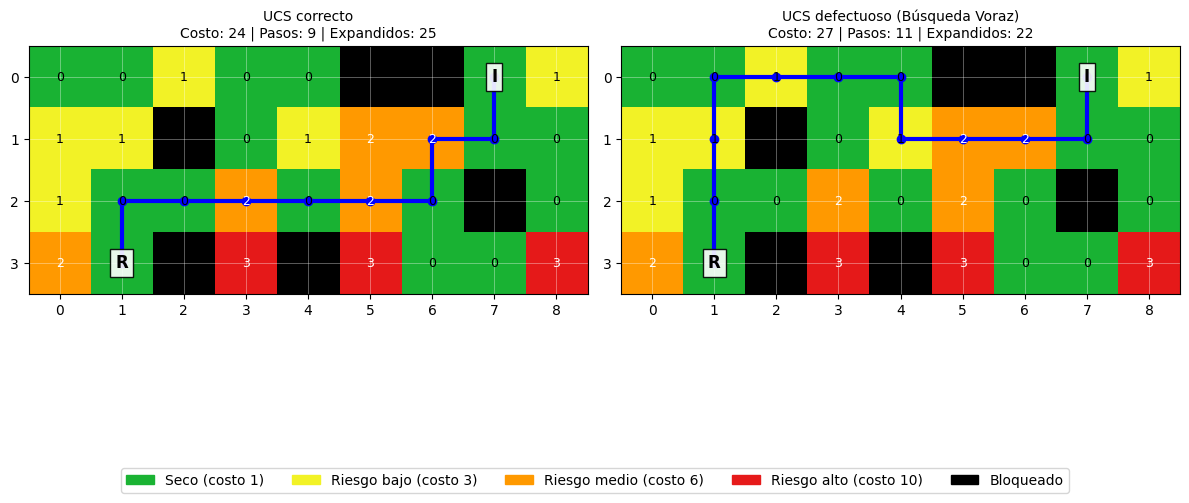


Parte 10b: la prueba detecta el error intencional


In [ ]:
import heapq
import itertools
import numpy as np

# =========================================================================
# 1. IMPLEMENTACIÓN DE UCS DEFECTUOSO (BÚSQUEDA VORAZ INTENCIONAL)
# =========================================================================
def ucs_defectuoso(mapa, inicio, refugio):
    """
    Versión defectuosa de UCS. El error intencional radica en que la prioridad
    en la cola 'heapq' es únicamente el costo de entrada de la celda vecina
    (COSTOS[mapa[vecino]]) en lugar de la suma acumulada (nuevo_costo).
    Esto transforma el algoritmo en una búsqueda de tipo ávida/voraz (Greedy).
    """
    if mapa[inicio] == BLOQUEADO:
        return (None, None, 0)

    if inicio == refugio:
        return ([inicio], 0, 1)

    contador_desempate = itertools.count()

    # Guardamos (costo_local_celda, desempate, celda_actual)
    # Al inicio el costo es 0
    cola_prioridad = []
    heapq.heappush(cola_prioridad, (0, next(contador_desempate), inicio))

    mejor_costo = {inicio: 0}
    padres = {inicio: None}

    expandidos = set()
    nodos_expandidos = 0
    encontrado = False

    while cola_prioridad:
        _, _, actual = heapq.heappop(cola_prioridad)

        if actual in expandidos:
            continue

        expandidos.add(actual)
        nodos_expandidos += 1

        if actual == refugio:
            encontrado = True
            break

        vecinos = obtener_vecinos(mapa, actual)

        for vecino in vecinos:
            # ERROR INTENCIONAL:
            # Calculamos nuevo_costo acumulado de forma interna para el diccionario de control,
            # pero al insertar en la cola de prioridad, la clave de ordenamiento es
            # únicamente el costo de la celda individual (terreno local).
            nuevo_costo = mejor_costo[actual] + COSTOS[mapa[vecino]]
            costo_prioridad_incorrecto = COSTOS[mapa[vecino]]

            if vecino not in mejor_costo or nuevo_costo < mejor_costo[vecino]:
                mejor_costo[vecino] = nuevo_costo
                padres[vecino] = actual
                # Insertamos usando el costo del paso en lugar del acumulado
                heapq.heappush(cola_prioridad, (costo_prioridad_incorrecto, next(contador_desempate), vecino))

    if not encontrado:
        return (None, None, nodos_expandidos)

    # Reconstrucción de la ruta
    ruta = []
    actual = refugio
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]
    ruta.reverse()

    costo_real = costo_de_ruta(mapa, ruta)
    return (ruta, costo_real, nodos_expandidos)

# =========================================================================
# 2. EJECUCIÓN EN LOS 500 MAPAS ALEATORIOS
# =========================================================================
rng = np.random.default_rng(2024)
total_mapas = 500
mapas_fichados = 0

primer_mapa_fallido = None
primer_inicio = None
primer_refugio = None
primeros_errores = []

for i in range(total_mapas):
    m_rand, ini_rand, ref_rand = generar_mapa_aleatorio(rng)

    # Ejecutar la verificación con el UCS defectuoso
    errs = verificar_mapa(m_rand, ini_rand, ref_rand, ucs_func=ucs_defectuoso)

    if len(errs) > 0:
        mapas_fichados += 1
        if primer_mapa_fallido is None:
            primer_mapa_fallido = m_rand.copy()
            primer_inicio = ini_rand
            primer_refugio = ref_rand
            primeros_errores = errs

# =========================================================================
# 3. COMPROBACIÓN MEDIANTE ASSERT E IMPRESIÓN
# =========================================================================
print(f"=== VERIFICACIÓN DE UCS DEFECTUOSO ===")
print(f"Mapas en los que se detectaron fallas: {mapas_fichados} de {total_mapas}")

assert mapas_fichados >= 1, "La prueba falló: el verificador no detectó el error intencional en ningún mapa."

print(f"\nErrores reportados en el primer mapa detectado como defectuoso:")
for e in primeros_errores:
    print(f" - {e}")

# =========================================================================
# 4. VISUALIZACIÓN COMPARATIVA DEL ERROR
# =========================================================================
# Resolvemos las rutas del primer mapa fallido para compararlas lado a lado
res_ucs_correcto = ucs(primer_mapa_fallido, primer_inicio, primer_refugio)
res_ucs_defectuoso = ucs_defectuoso(primer_mapa_fallido, primer_inicio, primer_refugio)

resultados_comparar = {
    "UCS correcto": res_ucs_correcto,
    "UCS defectuoso (Búsqueda Voraz)": res_ucs_defectuoso
}

print(f"\nComparación visual para el mapa de tamaño {primer_mapa_fallido.shape} con inicio {primer_inicio} y refugio {primer_refugio}:")
comparar_visual(primer_mapa_fallido, primer_inicio, primer_refugio, resultados_comparar)

# =========================================================================
# 5. MENSAJE DE ÉXITO
# =========================================================================
print("\nParte 10b: la prueba detecta el error intencional")

Filas totales antes de limpiar duplicados: 36
Filas finales después de limpiar: 21 (Se eliminaron 15 duplicados)

Escenarios detectados: ['1. Ruta disponible', '2a. Se bloquea (8,5)', '2b. Se bloquea (2,5)', '3. Refugio inaccesible', '4. Sube el riesgo del corredor sur', '5. El camino corto no es el mejor', '5b. Si el riesgo no pesara (todos los costos = 1)']

=== TABLA COMPARATIVA COMPLETA ===


Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
1. Ruta disponible,BFS,Sí,Sí,32,9,57
1. Ruta disponible,DFS,Sí,Sí,34,17,18
1. Ruta disponible,UCS,Sí,Sí,21,21,71
"2a. Se bloquea (8,5)",BFS,Sí,Sí,32,9,57
"2a. Se bloquea (8,5)",DFS,Sí,Sí,34,17,18
"2a. Se bloquea (8,5)",UCS,Sí,Sí,32,9,64
"2b. Se bloquea (2,5)",BFS,Sí,Sí,57,21,88
"2b. Se bloquea (2,5)",DFS,Sí,Sí,59,29,30
"2b. Se bloquea (2,5)",UCS,Sí,Sí,21,21,71
3. Refugio inaccesible,BFS,No,N/A,None,None,88



=== RESUMEN DE COSTOS POR ALGORITMO ===


Algoritmo,BFS,DFS,UCS
Escenario,,,
1. Ruta disponible,32,34,21
"2a. Se bloquea (8,5)",32,34,32
"2b. Se bloquea (2,5)",57,59,21
3. Refugio inaccesible,None,None,None
4. Sube el riesgo del corredor sur,32,34,32
5. El camino corto no es el mejor,31,31,8
5b. Si el riesgo no pesara (todos los costos = 1),4,4,4



=== RESUMEN DE NODOS EXPANDIDOS ===


Algoritmo,BFS,DFS,UCS
Escenario,,,
1. Ruta disponible,57,18,71
"2a. Se bloquea (8,5)",57,18,64
"2b. Se bloquea (2,5)",88,30,71
3. Refugio inaccesible,88,88,88
4. Sube el riesgo del corredor sur,57,18,69
5. El camino corto no es el mejor,8,5,9
5b. Si el riesgo no pesara (todos los costos = 1),8,5,8


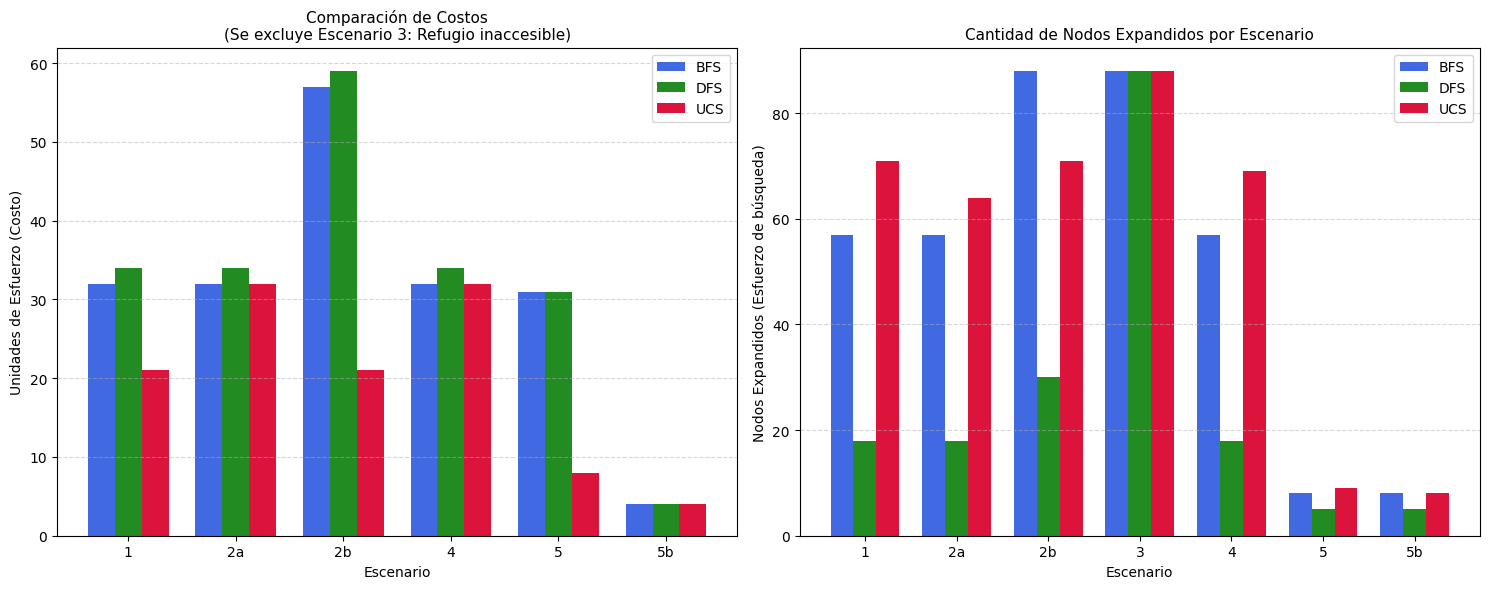

Parte 11a: la tabla comparativa pasó las comprobaciones


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================================
# 1. CONSOLIDACIÓN Y LIMPIEZA DE DATOS
# =========================================================================
# Concatenamos todas las tablas generadas en los escenarios
tabla_final_sucia = pd.concat(TABLAS, ignore_index=True)
filas_antes = len(tabla_final_sucia)
print(f"Filas totales antes de limpiar duplicados: {filas_antes}")

# Eliminamos duplicados quedándonos con la última versión de cada par (Escenario, Algoritmo)
tabla_final = tabla_final_sucia.drop_duplicates(subset=["Escenario", "Algoritmo"], keep="last").copy()
filas_despues = len(tabla_final)
eliminadas = filas_antes - filas_despues
print(f"Filas finales después de limpiar: {filas_despues} (Se eliminaron {eliminadas} duplicados)\n")

# =========================================================================
# 2. VALIDACIONES DE LA ESTRUCTURA DE LA TABLA
# =========================================================================
escenarios_encontrados = tabla_final["Escenario"].unique()
print(f"Escenarios detectados: {list(escenarios_encontrados)}\n")

# Comprobación de tamaño total
assert len(tabla_final) == 21, f"Se esperaban exactamente 21 filas, pero hay {len(tabla_final)}"

# Comprobación de que cada escenario tiene exactamente los 3 algoritmos
for esc in escenarios_encontrados:
    df_esc = tabla_final[tabla_final["Escenario"] == esc]
    algs_esc = set(df_esc["Algoritmo"])
    assert algs_esc == {"BFS", "DFS", "UCS"}, f"El escenario '{esc}' no tiene la combinación correcta de algoritmos: {algs_esc}"

# =========================================================================
# 3. MOSTRAR TABLA FINAL SIN ÍNDICE
# =========================================================================
print("=== TABLA COMPARATIVA COMPLETA ===")
display(tabla_final.style.hide(axis='index'))

# ==============================================================
# 3b. COMPROBACIONES SOBRE LA TABLA CONSOLIDADA
# ==============================================================
# Costo y Pasos como números (en el escenario 3 son None y pasan a NaN)
df_temp = tabla_final.copy()
df_temp["Costo"] = pd.to_numeric(df_temp["Costo"], errors="coerce")
df_temp["Pasos"] = pd.to_numeric(df_temp["Pasos"], errors="coerce")

# Índice (Escenario, Algoritmo) para consultar cualquier valor con .loc
df_check = df_temp.set_index(["Escenario", "Algoritmo"])

# A. En cada escenario con ruta: las rutas son válidas y
#    UCS nunca cuesta más que BFS ni que DFS
for esc in df_temp["Escenario"].unique():
    if df_check.loc[(esc, "UCS"), "¿Hay ruta?"] == "Sí":
        for alg in ["BFS", "DFS", "UCS"]:
            assert df_check.loc[(esc, alg), "¿Válida?"] == "Sí", \
                f"{esc}: la ruta de {alg} no es válida"
        costo_ucs = df_check.loc[(esc, "UCS"), "Costo"]
        for otro in ["BFS", "DFS"]:
            costo_otro = df_check.loc[(esc, otro), "Costo"]
            assert costo_ucs <= costo_otro, \
                f"{esc}: UCS ({costo_ucs}) cuesta más que {otro} ({costo_otro})"

# B. Escenario 3 (refugio inaccesible): ninguno encuentra ruta y los tres
#    expanden las 88 celdas alcanzables (calculado a mano)
for alg in ["BFS", "DFS", "UCS"]:
    fila = df_check.loc[("3. Refugio inaccesible", alg)]
    assert fila["¿Hay ruta?"] == "No", f"Escenario 3: {alg} reporta una ruta"
    assert fila["Nodos expandidos"] == 88, \
        f"Escenario 3: {alg} expandió {fila['Nodos expandidos']} nodos, no 88"

# C. Valores concretos calculados a mano o vistos en las ejecuciones
esperados = [
    # (escenario, algoritmo, columna, valor esperado)
    ("1. Ruta disponible", "BFS", "Costo", 32),
    ("1. Ruta disponible", "DFS", "Costo", 34),
    ("1. Ruta disponible", "UCS", "Costo", 21),
    ("2a. Se bloquea (8,5)", "UCS", "Costo", 32),
    ("2b. Se bloquea (2,5)", "BFS", "Pasos", 21),
    ("2b. Se bloquea (2,5)", "UCS", "Costo", 21),
    ("5. El camino corto no es el mejor", "BFS", "Costo", 31),
    ("5. El camino corto no es el mejor", "UCS", "Costo", 8),
]
for esc, alg, col, valor in esperados:
    obtenido = df_check.loc[(esc, alg), col]
    assert obtenido == valor, \
        f"{esc} - {alg} - {col}: esperado {valor}, obtenido {obtenido}"

# =========================================================================
# 4. TABLAS RESUMEN (PIVOT TABLES)
# =========================================================================
# Definimos el orden lógico de los escenarios para mantener consistencia
orden_escenarios = [
    "1. Ruta disponible",
    "2a. Se bloquea (8,5)",
    "2b. Se bloquea (2,5)",
    "3. Refugio inaccesible",
    "4. Sube el riesgo del corredor sur",
    "5. El camino corto no es el mejor",
    "5b. Si el riesgo no pesara (todos los costos = 1)"
]

# Aseguramos que 'Escenario' sea categórico para respetar este orden exacto en los pivotes
tabla_final["Escenario"] = pd.Categorical(tabla_final["Escenario"], categories=orden_escenarios, ordered=True)

# Tabla resumen (a): Costo
pivot_costo = tabla_final.pivot(index="Escenario", columns="Algoritmo", values="Costo")
print("\n=== RESUMEN DE COSTOS POR ALGORITMO ===")
display(pivot_costo)

# Tabla resumen (b): Nodos expandidos
pivot_nodos = tabla_final.pivot(index="Escenario", columns="Algoritmo", values="Nodos expandidos")
print("\n=== RESUMEN DE NODOS EXPANDIDOS ===")
display(pivot_nodos)

# =========================================================================
# 5. GRÁFICAS COMPARATIVAS DE BARRAS AGRUPADAS
# =========================================================================
# Preparamos las etiquetas cortas extrayendo el prefijo antes del primer punto
etiquetas_grafico = [esc.split(".")[0] for esc in orden_escenarios]

# Para la gráfica de costos, filtramos el escenario "3. Refugio inaccesible"
escenarios_costo = [esc for esc in orden_escenarios if esc != "3. Refugio inaccesible"]
etiquetas_costo = [esc.split(".")[0] for esc in escenarios_costo]

# Extraemos los datos numéricos alineados
costos_bfs = [pivot_costo.loc[esc, "BFS"] for esc in escenarios_costo]
costos_dfs = [pivot_costo.loc[esc, "DFS"] for esc in escenarios_costo]
costos_ucs = [pivot_costo.loc[esc, "UCS"] for esc in escenarios_costo]

nodos_bfs = [pivot_nodos.loc[esc, "BFS"] for esc in orden_escenarios]
nodos_dfs = [pivot_nodos.loc[esc, "DFS"] for esc in orden_escenarios]
nodos_ucs = [pivot_nodos.loc[esc, "UCS"] for esc in orden_escenarios]

# Configuración de posiciones para las barras
x_costo = np.arange(len(etiquetas_costo))
x_nodos = np.arange(len(etiquetas_grafico))
ancho_barra = 0.25

fig, (ax_c, ax_n) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot izquierdo: Costo (Excluyendo Escenario 3)
ax_c.bar(x_costo - ancho_barra, costos_bfs, ancho_barra, label='BFS', color='royalblue')
ax_c.bar(x_costo, costos_dfs, ancho_barra, label='DFS', color='forestgreen')
ax_c.bar(x_costo + ancho_barra, costos_ucs, ancho_barra, label='UCS', color='crimson')
ax_c.set_title("Comparación de Costos\n(Se excluye Escenario 3: Refugio inaccesible)", fontsize=11)
ax_c.set_xlabel("Escenario")
ax_c.set_ylabel("Unidades de Esfuerzo (Costo)")
ax_c.set_xticks(x_costo)
ax_c.set_xticklabels(etiquetas_costo)
ax_c.legend()
ax_c.grid(axis='y', linestyle='--', alpha=0.5)

# Subplot derecho: Nodos Expandidos (Todos los escenarios)
ax_n.bar(x_nodos - ancho_barra, nodos_bfs, ancho_barra, label='BFS', color='royalblue')
ax_n.bar(x_nodos, nodos_dfs, ancho_barra, label='DFS', color='forestgreen')
ax_n.bar(x_nodos + ancho_barra, nodos_ucs, ancho_barra, label='UCS', color='crimson')
ax_n.set_title("Cantidad de Nodos Expandidos por Escenario", fontsize=11)
ax_n.set_xlabel("Escenario")
ax_n.set_ylabel("Nodos Expandidos (Esfuerzo de búsqueda)")
ax_n.set_xticks(x_nodos)
ax_n.set_xticklabels(etiquetas_grafico)
ax_n.legend()
ax_n.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# ==============================================================
# 6. GUARDAR RESULTADOS Y CONFIRMAR
# ==============================================================
tabla_final.to_csv("resultados_comparacion.csv", index=False)
df_cargado = pd.read_csv("resultados_comparacion.csv")
assert len(df_cargado) == 21, f"El CSV tiene {len(df_cargado)} filas, se esperaban 21"

print("Parte 11a: la tabla comparativa pasó las comprobaciones")



=== ESTADÍSTICAS DE ALCANZABILIDAD ===
Mapas alcanzables: 421
Mapas no alcanzables: 79

=== MÉTRICAS PROMEDIO Y MEDIANAS POR ALGORITMO ===


Costo         Pasos        Nodos expandidos       
            mean median   mean median             mean median
Algoritmo                                                    
BFS        15.52   12.0   5.15    4.0            18.33   15.0
DFS        39.72   30.0  12.11   10.0            17.39   14.0
UCS        13.11   10.0   5.40    5.0            16.23   12.0


=== COMPARACIÓN DE COSTOS ===
UCS vs BFS:
  - UCS tiene menor costo: 148 (35.15%)
  - UCS tiene igual costo: 273 (64.85%)
  - UCS tiene mayor costo: 0 (0.00%)

UCS vs DFS:
  - UCS tiene menor costo: 311 (73.87%)
  - UCS tiene igual costo: 110 (26.13%)
  - UCS tiene mayor costo: 0 (0.00%)

=== COMPARACIÓN DE PASOS (DISTANCIA) ===
BFS vs UCS:
  - BFS tiene menos pasos: 40 (9.50%)
  - BFS tiene igual pasos: 381 (90.50%)
  - BFS tiene más pasos: 0 (0.00%)



/tmp/ipykernel_4359/2224102567.py:129: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax1.boxplot(data_costo, labels=["BFS", "DFS", "UCS"])
/tmp/ipykernel_4359/2224102567.py:136: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot(data_nodos, labels=["BFS", "DFS", "UCS"])


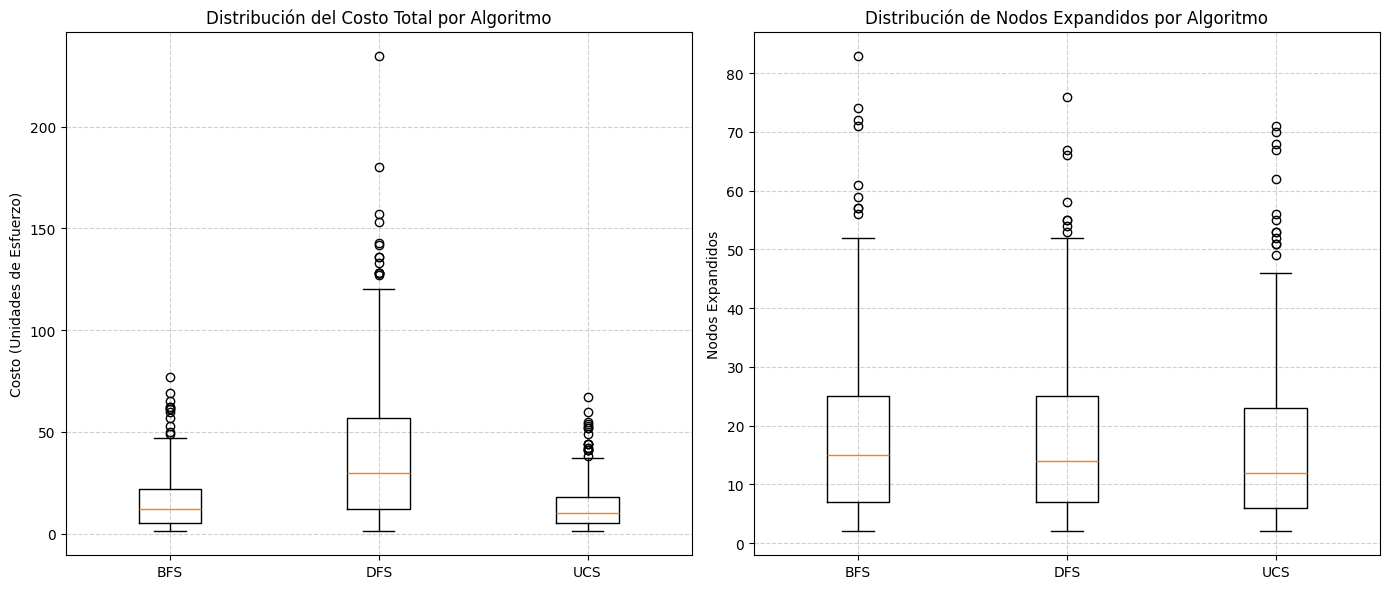


Parte 11b: la comparación sobre mapas aleatorios pasó las comprobaciones


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================================
# 1. SIMULACIÓN DE 500 MAPAS ALEATORIOS
# =========================================================================
rng = np.random.default_rng(2024)

total_mapas = 500
alcanzables = 0
no_alcanzables = 0
resultados_lista = []

for mapa_id in range(total_mapas):
    # Generamos un mapa aleatorio con la semilla de referencia
    m_rand, ini_rand, ref_rand = generar_mapa_aleatorio(rng)

    # Clasificamos según alcanzabilidad
    if refugio_es_alcanzable(m_rand, ini_rand, ref_rand):
        alcanzables += 1

        # Ejecutamos los tres algoritmos en el mapa alcanzable
        r_bfs, c_bfs, n_bfs = bfs(m_rand, ini_rand, ref_rand)
        r_dfs, c_dfs, n_dfs = dfs(m_rand, ini_rand, ref_rand)
        r_ucs, c_ucs, n_ucs = ucs(m_rand, ini_rand, ref_rand)

        # Guardamos la información de cada algoritmo
        resultados_lista.append({
            "mapa_id": mapa_id,
            "Algoritmo": "BFS",
            "Costo": c_bfs,
            "Pasos": len(r_bfs) - 1 if r_bfs is not None else None,
            "Nodos expandidos": n_bfs
        })
        resultados_lista.append({
            "mapa_id": mapa_id,
            "Algoritmo": "DFS",
            "Costo": c_dfs,
            "Pasos": len(r_dfs) - 1 if r_dfs is not None else None,
            "Nodos expandidos": n_dfs
        })
        resultados_lista.append({
            "mapa_id": mapa_id,
            "Algoritmo": "UCS",
            "Costo": c_ucs,
            "Pasos": len(r_ucs) - 1 if r_ucs is not None else None,
            "Nodos expandidos": n_ucs
        })
    else:
        no_alcanzables += 1

# =========================================================================
# 2. CONSTRUCCIÓN Y VERIFICACIÓN DE DF_ALEATORIOS
# =========================================================================
df_aleatorios = pd.DataFrame(resultados_lista)

print(f"=== ESTADÍSTICAS DE ALCANZABILIDAD ===")
print(f"Mapas alcanzables: {alcanzables}")
print(f"Mapas no alcanzables: {no_alcanzables}\n")

# Validación del conteo exacto esperado con la semilla 2024
assert alcanzables == 421 and no_alcanzables == 79, \
    f"Error: se esperaban 421 alcanzables y 79 no alcanzables, pero se obtuvieron {alcanzables} y {no_alcanzables}"

# =========================================================================
# 3. TABLA RESUMEN DE MÉTRICAS (MEDIA Y MEDIANA)
# =========================================================================
tabla_resumen = df_aleatorios.groupby("Algoritmo")[["Costo", "Pasos", "Nodos expandidos"]].agg(["mean", "median"])
print("=== MÉTRICAS PROMEDIO Y MEDIANAS POR ALGORITMO ===")
display(tabla_resumen.round(2))
print()

# =========================================================================
# 4. COMPARATIVAS DE COSTO (UCS contra BFS y DFS)
# =========================================================================
pivot_costo = df_aleatorios.pivot(index="mapa_id", columns="Algoritmo", values="Costo")

# Comparación UCS vs BFS
ucs_menor_bfs = (pivot_costo["UCS"] < pivot_costo["BFS"]).sum()
ucs_igual_bfs = (pivot_costo["UCS"] == pivot_costo["BFS"]).sum()
ucs_mayor_bfs = (pivot_costo["UCS"] > pivot_costo["BFS"]).sum()

# Comparación UCS vs DFS
ucs_menor_dfs = (pivot_costo["UCS"] < pivot_costo["DFS"]).sum()
ucs_igual_dfs = (pivot_costo["UCS"] == pivot_costo["DFS"]).sum()
ucs_mayor_dfs = (pivot_costo["UCS"] > pivot_costo["DFS"]).sum()

print("=== COMPARACIÓN DE COSTOS ===")
print(f"UCS vs BFS:")
print(f"  - UCS tiene menor costo: {ucs_menor_bfs} ({ucs_menor_bfs / alcanzables * 100:.2f}%)")
print(f"  - UCS tiene igual costo: {ucs_igual_bfs} ({ucs_igual_bfs / alcanzables * 100:.2f}%)")
print(f"  - UCS tiene mayor costo: {ucs_mayor_bfs} ({ucs_mayor_bfs / alcanzables * 100:.2f}%)")

print(f"\nUCS vs DFS:")
print(f"  - UCS tiene menor costo: {ucs_menor_dfs} ({ucs_menor_dfs / alcanzables * 100:.2f}%)")
print(f"  - UCS tiene igual costo: {ucs_igual_dfs} ({ucs_igual_dfs / alcanzables * 100:.2f}%)")
print(f"  - UCS tiene mayor costo: {ucs_mayor_dfs} ({ucs_mayor_dfs / alcanzables * 100:.2f}%)\n")

# Aserción teórica del costo óptimo de UCS
assert ucs_mayor_bfs == 0, f"¡Error! UCS reportó mayor costo que BFS en {ucs_mayor_bfs} mapas."
assert ucs_mayor_dfs == 0, f"¡Error! UCS reportó mayor costo que DFS en {ucs_mayor_dfs} mapas."

# =========================================================================
# 5. COMPARATIVAS DE PASOS (BFS contra UCS)
# =========================================================================
pivot_pasos = df_aleatorios.pivot(index="mapa_id", columns="Algoritmo", values="Pasos")

bfs_menor_ucs = (pivot_pasos["BFS"] < pivot_pasos["UCS"]).sum()
bfs_igual_ucs = (pivot_pasos["BFS"] == pivot_pasos["UCS"]).sum()
bfs_mayor_ucs = (pivot_pasos["BFS"] > pivot_pasos["UCS"]).sum()

print("=== COMPARACIÓN DE PASOS (DISTANCIA) ===")
print(f"BFS vs UCS:")
print(f"  - BFS tiene menos pasos: {bfs_menor_ucs} ({bfs_menor_ucs / alcanzables * 100:.2f}%)")
print(f"  - BFS tiene igual pasos: {bfs_igual_ucs} ({bfs_igual_ucs / alcanzables * 100:.2f}%)")
print(f"  - BFS tiene más pasos: {bfs_mayor_ucs} ({bfs_mayor_ucs / alcanzables * 100:.2f}%)\n")

# Aserción teórica de optimalidad en pasos para BFS frente a UCS
assert bfs_mayor_ucs == 0, f"¡Error! BFS obtuvo más pasos que UCS en {bfs_mayor_ucs} mapas."

# =========================================================================
# 6. VISUALIZACIÓN MEDIANTE DIAGRAMAS DE CAJA (BOXPLOTS)
# =========================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot para Costos
data_costo = [df_aleatorios[df_aleatorios["Algoritmo"] == alg]["Costo"] for alg in ["BFS", "DFS", "UCS"]]
ax1.boxplot(data_costo, labels=["BFS", "DFS", "UCS"])
ax1.set_title("Distribución del Costo Total por Algoritmo")
ax1.set_ylabel("Costo (Unidades de Esfuerzo)")
ax1.grid(True, linestyle="--", alpha=0.6)

# Boxplot para Nodos Expandidos
data_nodos = [df_aleatorios[df_aleatorios["Algoritmo"] == alg]["Nodos expandidos"] for alg in ["BFS", "DFS", "UCS"]]
ax2.boxplot(data_nodos, labels=["BFS", "DFS", "UCS"])
ax2.set_title("Distribución de Nodos Expandidos por Algoritmo")
ax2.set_ylabel("Nodos Expandidos")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# =========================================================================
# 7. EXPORTAR A CSV Y MENSAJE DE CONFIRMACIÓN
# =========================================================================
df_aleatorios.to_csv("resultados_aleatorios.csv", index=False)
print("\nParte 11b: la comparación sobre mapas aleatorios pasó las comprobaciones")
